# HADES: case study

Four scenarios x two pathways (A: HTC, then anaerobic digestion of the process water; B: anaerobic digestion, then HTC of the digestate). Functional unit: 1 t of wet feedstock, Quebec. Background: ecoinvent 3.12 cut-off (Brightway project `ei3.12 for DDI`); impact assessment: IMPACT World+ 2.2.1 (regionalized). Process model: `ADM1/system_builder.py`; HTC surrogate: `ML training scripts and models/htc_surrogate.py`.

Run order: 1 (optional), 2, 3, then 4 to 9 in any order, except that section 7 must run before section 8 (section 8 rebuilds the foreground databases). Restart the kernel before section 2 after any change to the code in `ADM1/`.

## 1. Background check

In [35]:
# =============================================================================
# 1. BACKGROUND CHECK (optional, ~1 min): ecoinvent scores must be realistic
# =============================================================================
import bw2data as bd
from bw2calc import LCA

PROJECT, EI = "ei3.12 for DDI", "ecoinvent-3.12-cutoff"
M_GWP = ("IMPACT World+ Midpoint 2.2.1_regionalized for ecoinvent v3.12", "Midpoint", "Climate change, short term")
M_HH  = ("IMPACT World+ Damage 2.2.1_regionalized for ecoinvent v3.12", "Human health", "Total human health")
M_EQ  = ("IMPACT World+ Damage 2.2.1_regionalized for ecoinvent v3.12", "Ecosystem quality", "Total ecosystem quality")

bd.projects.set_current(PROJECT)
ok = True
for m in (M_GWP, M_HH, M_EQ):
    if m not in bd.methods:
        ok = False
        print("MISSING method:", m)
if not ok:
    print("IW+ methods in this project:", sorted({x[0] for x in bd.methods if "World+" in x[0]}))
else:
    ei = bd.Database(EI)
    # (ecoinvent dataset, plausible GWP range per unit)
    tests = [("market for electricity, medium voltage", (0.0, 0.05)),       # QC hydro grid
             ("market for heat, district or industrial, natural gas", (0.05, 0.10))]
    for name, (lo, hi) in tests:
        act = next(a for a in ei if a["name"] == name and a["location"] == "CA-QC")
        lca = LCA({act: 1}, M_GWP); lca.lci(); lca.lcia()
        flag = "PASS" if lo <= lca.score <= hi else "FAIL"
        print(f"{flag}  {lca.score:.4g} kg CO2 eq per {act['unit']}  (expected {lo}-{hi})  {name}")

PASS  0.02743 kg CO2 eq per kilowatt hour  (expected 0.0-0.05)  market for electricity, medium voltage
PASS  0.06904 kg CO2 eq per megajoule  (expected 0.05-0.1)  market for heat, district or industrial, natural gas


## 2. Case study run (writes the results and contributions CSV)

In [36]:
# =============================================================================
# 2. CASE STUDY RUN
# 4 scenarios x 2 pathways, FU = 1 t wet feedstock at the gate (Quebec)
#   A = HTC, then AD of the process water   |   B = AD, then HTC of the digestate
# Output: case_study_results.csv (all metadata), case_study_contributions.csv
#         (impacts by contribution category) + summary tables below
# =============================================================================
import os, sys, importlib.util
import numpy as np
import pandas as pd
import bw2data as bd
from bw2calc import LCA

# ---------------------------------------------------------------- 0. SETTINGS
HADES_DIR = os.getcwd() if os.path.isdir(os.path.join(os.getcwd(), "ADM1")) else os.path.dirname(os.getcwd())   # repository root
PROJECT = "ei3.12 for DDI"          # Brightway project
EI_NAME = "ecoinvent-3.12-cutoff"   # background database
LOC = ["CA-QC", "CA", "RoW", "GLO"]                        # dataset location priority
OUT_CSV = os.path.join(HADES_DIR, "results", "case_study_results.csv")

FEEDS = {   # case study feedstocks, % dry basis (O by difference), WC % wet basis
    "food_waste": dict(C_feed=38.25, H_feed=5.47, N_feed=3.66, S_feed=0.50, Ash_feed=9.10,
                       VM_feed=82.6, FC_feed=8.3, WC=85.0),
    "ofmsw":      dict(C_feed=45.00, H_feed=6.00, N_feed=2.50, S_feed=0.20, Ash_feed=5.30,
                       VM_feed=78.0, FC_feed=16.7, WC=70.0),
}
SCENARIOS = {   # name: feedstock, HTC temperature (C), AD hydraulic retention time (d)
    "S1 Base FW":   dict(feed="food_waste", T_HTC=180, HRT=30),
    "S2 OFMSW":     dict(feed="ofmsw",      T_HTC=180, HRT=30),
    "S3 HTC 250 C": dict(feed="food_waste", T_HTC=250, HRT=30),
    "S4 HRT 50 d":  dict(feed="food_waste", T_HTC=180, HRT=50),
}
FIXED = dict(RT_HTC=60, target_moisture_HTC=0.85, MC_char=0.35, target_MC_char_dry=0.10,
             COD_conc_target=10.0, TS_target=0.08, ISR_batch=2.0, t_spinup=400)

IW_DMG = "IMPACT World+ Damage 2.2.1_regionalized for ecoinvent v3.12"
IW_MID = "IMPACT World+ Midpoint 2.2.1_regionalized for ecoinvent v3.12"
METHODS = {"GWP100 (kg CO2 eq)":       (IW_MID, "Midpoint", "Climate change, short term"),
           "Human health (DALY)":      (IW_DMG, "Human health", "Total human health"),
           "Ecosystem quality (PDF.m2.yr)": (IW_DMG, "Ecosystem quality", "Total ecosystem quality")}

# ---------------------------------------------------------------- 1. HADES CODE
os.chdir(HADES_DIR)
spec = importlib.util.spec_from_file_location("system_builder", os.path.join("ADM1", "system_builder.py"))
sb = importlib.util.module_from_spec(spec); sys.modules["system_builder"] = sb; spec.loader.exec_module(sb)
ML_MODULE = os.path.join(HADES_DIR, "ML training scripts and models", "htc_surrogate.py")   # HTC surrogate
bwl, hce = sb.bwl, sb.hce

# ---------------------------------------------------------------- 2. BACKGROUND (ecoinvent)
bd.projects.set_current(PROJECT)
ei, bios = bd.Database(EI_NAME), bd.Database("biosphere3")
for m in METHODS.values():
    if m not in bd.methods:
        _iw = sorted({x[0] for x in bd.methods if "World+" in x[0]})
        raise KeyError(f"LCIA method not found in project {PROJECT!r}: {m}\nIMPACT World+ methods here: {_iw}")
find = lambda q, prio=LOC, nf=None: bwl.find_process(ei, q, prio, name_filter=nf)
bg = dict(
    elec=find("market for electricity, medium voltage", nf="market for electricity, medium voltage"),
    coal_heat=find("heat production, at hard coal industrial furnace 1-10MW", nf="hard coal industrial furnace"),
    ad_heat=find("heat production, natural gas", nf="heat production, natural gas"),
    ng_heat_market=find("market for heat, district or industrial, natural gas",
                        nf="market for heat, district or industrial, natural gas"),
    biomethane_heat_ref=find("heat production, biomethane, at boiler condensing modulating",
                             ["RoW", "GLO"] + LOC, nf="biomethane"),
    tap_water=find("market for tap water", nf="market for tap water"),
    wastewater_treat=find("treatment of wastewater, average", nf="treatment of wastewater, average"),
    psa_ref=find("biogas purification to biomethane by pressure swing adsorption", ["RoW", "GLO"] + LOC),
)
bg["ad_elec"] = bg["drying_heat"] = bg["elec"]             # AD and dryer run on grid electricity
heat_mix_qc = bwl.resolve_heat_mix(ei, hce.HEAT_MIX_DATASETS, hce.QC_HEAT_MIX.keys(), LOC)
try:
    ash_disposal = bwl.find_exact(ei, "market for wood ash mixture, pure", LOC)
except LookupError:
    ash_disposal = None
    print("WARNING: ash disposal dataset not found, boiler ash omitted")
co2_air = bwl.get_flow("Carbon dioxide, non-fossil", ("air",), bwl.CORE_FLOW_LOCATIONS)
co_air = bwl.get_flow("Carbon monoxide, non-fossil", ("air",), bwl.CORE_FLOW_LOCATIONS)
print(f"Regionalized biosphere present: {bwl.SPATIAL_FLOW_DB in bd.databases}")

# ---------------------------------------------------------------- 3. FOREGROUND (one database per pathway)
def foreground(P):
    name = f"Pathway{P}"
    if name not in bd.databases:
        bd.Database(name).register()
    db = bd.Database(name)
    g = lambda code, label, unit: sb.get_or_create(db, code, label, unit)
    fg = dict(
        htc_reactor=g("htc_reactor", "HTC reactor", "unit"),
        drying=g("hydrochar_drying", "Hydrochar drying", "unit"),
        heat_prod=g("heat_prod_hydrochar", "Heat production from hydrochar", "megajoule"),
        sub_heat_coal=g("substitute_heat_coal", "Hard coal heat (not used in the case study)", "megajoule"),
        ad_process=g("anaerobic_digestion", "Anaerobic digestion (ADM1)", "unit"),
        dewatering=g("digestate dewatering", "Digestate dewatering", "unit"),
        biogas_upgrading=g("biogas_upgrading", "Biogas upgrading (PSA)", "unit"),
        heat_biomethane=g("heat_biomethane", "Heat production from biomethane", "megajoule"),
        heat_naturalgas=g("heat_naturalgas", "Natural gas heat (substituted)", "megajoule"),
        qc_heat_mix=g("qc_industrial_heat_mix", "Quebec industrial combustion heat mix", "megajoule"),
        waste_treatment=g("waste_treatment_1kg", "Waste treatment of organic waste (HTC-AD system)", "kilogram"),
    )
    # clear result fields stored on the activity by previous runs, so the CSV
    # only holds values written by this run
    wt0 = fg["waste_treatment"]
    keep = {"name", "code", "unit", "database", "type", "location", "reference product", "id"}
    for k in [k for k in list(wt0._data) if k not in keep]:
        del wt0._data[k]
    wt0.save()
    return name, fg

# ---------------------------------------------------------------- 3b. CONTRIBUTION ANALYSIS
OUT_CONTRIB = os.path.join(HADES_DIR, "results", "case_study_contributions.csv")
CATS = ["HTC and drying (electricity)", "Digester heat (natural gas)",
        "Dilution water and wastewater treatment", "Direct emissions (HTC off-gas, digestion, upgrading)",
        "Hydrochar combustion and ash disposal", "Other (AD and dewatering electricity, PSA)",
        "Credit: Quebec industrial heat mix", "Credit: natural gas heat"]
_unit_score, _cf = {}, {}

def unit_score(act, m):
    """Score of 1 unit of a background activity (cached across runs)."""
    k = (act.key, m)
    if k not in _unit_score:
        l = LCA({act: 1}, m); l.lci(); l.lcia(); _unit_score[k] = l.score
    return _unit_score[k]

def cf_of(flow_key, m):
    """Characterization factor of a biosphere flow (0 if the method has none)."""
    if m not in _cf:
        _cf[m] = {(tuple(k) if isinstance(k, (list, tuple)) else bd.get_activity(k).key): v
                  for k, v, *_ in bd.Method(m).load()}
    return _cf[m].get(flow_key, 0.0)

def category(parent_code, exc):
    name, t = exc.input["name"].lower(), exc["type"]
    if parent_code == "qc_industrial_heat_mix": return CATS[6]
    if parent_code == "heat_naturalgas": return CATS[7]
    if parent_code == "heat_prod_hydrochar" or "wood ash" in name: return CATS[4]
    if t == "biosphere": return CATS[3]
    if "tap water" in name or "wastewater" in name: return CATS[2]
    if parent_code in ("htc_reactor", "hydrochar_drying") and "electricity" in name: return CATS[0]
    if parent_code == "anaerobic_digestion" and "heat" in name: return CATS[1]
    return CATS[5]

def contributions(wt, FG, m):
    """Walk the foreground tree: background input = amount x unit score,
    foreground emission = amount x CF. Foreground production amounts are 1."""
    out = dict.fromkeys(CATS, 0.0)
    def walk(act, amount, parent_code):
        for e in act.exchanges():
            if e["type"] == "production" or e["amount"] == 0:
                continue
            a, inp = amount * e["amount"], e.input
            if e["type"] == "biosphere":
                out[category(parent_code, e)] += a * cf_of(inp.key, m)
            elif inp.key[0] == FG:
                walk(inp, a, inp.key[1])
            else:
                out[category(parent_code, e)] += a * unit_score(inp, m)
    walk(wt, 1.0, "waste_treatment_1kg")
    return out

contrib_rows = []

# ---------------------------------------------------------------- 4. RUN
rows = []
for scen, s in SCENARIOS.items():
    f = dict(FEEDS[s["feed"]])
    feed = {**f, "O_feed": 100 - f["C_feed"] - f["H_feed"] - f["N_feed"] - f["S_feed"] - f["Ash_feed"]}
    for P in ("A", "B"):
        FG, fg = foreground(P)
        ctx = sb.SystemContext(
            ei=ei, bios=bios, FOREGROUND_DB=FG, **bg, co2_air=co2_air, co_air=co_air, **fg,
            PATHWAY=P, m_feedstock=1000.0, default_params=feed,
            ml_params={**feed, "T": s["T_HTC"], "RT": FIXED["RT_HTC"]},
            T_HTC=s["T_HTC"], RT_HTC=FIXED["RT_HTC"], target_moisture_HTC=FIXED["target_moisture_HTC"],
            MC_char=FIXED["MC_char"], target_MC_char_dry=FIXED["target_MC_char_dry"],
            COD_conc_target=FIXED["COD_conc_target"], ISR_batch=FIXED["ISR_batch"],
            feedstock_name=s["feed"], heat_mix_components_qc=heat_mix_qc, ash_disposal=ash_disposal,
            location_country="Canada", location_province="quebec", location_code="CA-QC")
        row = {"scenario": scen, "pathway": P, "feedstock": s["feed"], "T_HTC": s["T_HTC"],
               "HRT_d": s["HRT"], "status": "ok"}
        try:
            ss = sb.spinup_ss_state(ctx, pathway=P, adm1_HRT_days=s["HRT"], t_spinup=FIXED["t_spinup"],
                                    TS_target=FIXED["TS_target"], verbose=False, ml_module=ML_MODULE)
            wt, _, adm1_out, _, inv = sb.build_system(
                ctx, ml_module=ML_MODULE, adm1_mode="continuous", adm1_HRT_days=s["HRT"],
                adm1_ss_state=ss, ISR_batch=FIXED["ISR_batch"], TS_target=FIXED["TS_target"])
            for k, m in METHODS.items():
                lca = LCA({wt: 1}, m); lca.lci(); lca.lcia()
                row[k] = lca.score
            data = dict(getattr(wt, "_data", wt))
            row.update({k: v for k, v in data.items()
                        if isinstance(v, (int, float, str, bool, np.floating))
                        and k not in ("name", "code", "unit", "database", "type", "location")})
            row.update({f"char {k}": v for k, v in inv.items() if isinstance(v, (int, float, np.floating))})
            row.update(scenario=scen, pathway=P)        # scenario labels of this run
            for k, m in METHODS.items():
                c = contributions(wt, FG, m)
                tot = sum(c.values())
                if abs(tot - row[k]) > 1e-4 * max(1e-9, abs(row[k])):   # QA: closure of the breakdown
                    raise ValueError(f"[contribution] {scen}-{P} {k}: categories sum {tot:.6g} "
                                     f"!= LCA score {row[k]:.6g} (rel tol 1e-4)")
                contrib_rows += [dict(scenario=scen, pathway=P, indicator=k, category=cat, value=v)
                                 for cat, v in c.items()]
            row["ADM1 pH"] = (adm1_out.get("ss_state") or {}).get("pH")
        except Exception as e:
            row["status"] = f"FAILED: {type(e).__name__}: {e}"
        rows.append(row)
        print(f"{scen:13s} {P}  {row['status'][:60]:8s}  QA: {row.get('qa_flags', '') or 'none'}")

res = pd.DataFrame(rows)
res.to_csv(OUT_CSV, index=False)
print(f"\nSaved {len(res)} runs -> {OUT_CSV}")
pd.DataFrame(contrib_rows).to_csv(OUT_CONTRIB, index=False)
print(f"Saved contributions -> {OUT_CONTRIB}")

# ---------------------------------------------------------------- 5. SUMMARY TABLES
pd.set_option("display.width", 220, "display.max_columns", 30)
impact = res.pivot(index="scenario", columns="pathway", values=list(METHODS)).reindex(list(SCENARIOS))
print("\nImpacts per t wet feedstock (negative = net benefit)")
display(impact.style.format("{:.3g}"))
process_cols = {"char Y_char (%)": "char yield (% dry)", "char HHV_char (MJ/kg)": "char HHV (MJ/kg)",
                "HC_dry_yield": "dried char (kg)", "MJ_hydrochar": "char heat (MJ)",
                "biomethane_m3": "biomethane (Nm3)", "CH4_mass_AD": "CH4 (kg)",
                "E_HTC_elec_kWh": "HTC elec (kWh)", "E_dryer_heat_kWh": "dryer (kWh)",
                "Q_AD_util_MJ": "AD heat (MJ)",
                "ADM1 pH": "digester pH", "qa_flags": "QA flags"}
proc = res.set_index(["scenario", "pathway"])[[c for c in process_cols if c in res]].rename(columns=process_cols)
print("\nProcess results per t wet feedstock")
display(proc)


  [background] 'market for electricity, medium voltage' -> 'market for electricity, medium voltage' [CA-QC]
  [background] 'heat production, at hard coal industrial furnace 1-10MW' -> 'heat production, at hard coal industrial furnace 1-10MW' [CA-QC]
  [background] 'heat production, natural gas' -> 'heat production, natural gas, at boiler condensing modulating >100kW' [CA-QC]
  [background] 'market for heat, district or industrial, natural gas' -> 'market for heat, district or industrial, natural gas' [CA-QC]
  [background] 'heat production, biomethane, at boiler condensing modulating' -> 'heat production, biomethane, at boiler condensing modulating <100kW' [RoW]
  [background] 'market for tap water' -> 'market for tap water' [CA-QC]
  [background] 'treatment of wastewater, average' -> 'treatment of wastewater, average, wastewater treatment' [CA-QC]
  [background] 'biogas purification to biomethane by pressure swing adsorption' -> 'biogas purification to biomethane by pressure swing ads

ADM1 continuous:  45%|████████████████████████████▊                                   | 180/400 [00:16<00:19, 11.13d/s]



[run_adm1] Converged at t=180.0 d (6×HRT)

[run_adm1 continuous] CH4 = 155.92421 kg  (249.68467 m³)
[run_adm1 continuous] CO2 = 288.10398 kg  (167.76250 m³)
[run_adm1 continuous] NH3 = 2.59003 kg

=== SS DIAGNOSTIC ===
  X_ac      : 0.18645
  X_h2      : 0.08181
  X_pro     : 0.03367
  S_ac      : 0.08064
  S_pro     : 0.01651
  S_IN      : 0.06301
  S_nh3     : 0.00184
  pH        : 7.43356
  S_h2      : 0.00000
  --- PW-ADM1 sub-pools (SS) ---
  S_I_furan   : 0.0667 kgCOD/m³  K_I=1.5  I=0.957
  S_I_alcohol : 0.0667 kgCOD/m³  K_I=10.0  I=0.993
  S_I_phenol  : 0.0408 kgCOD/m³  K_I=1.0  I=0.961
  S_I_acid    : 0.1156 kgCOD/m³  K_I=10.0  I=0.989
  S_I_ketone  : 0.1980 kgCOD/m³  K_I=1.9  I=0.906
  S_I_humic   : 0.5692 kgCOD/m³  K_I=10.0  I=0.946
  I_tox (SS, combined): 0.7740  (77.4% of uninhibited rate)

[ADM1 results A | continuous] CH4=155.9242 kg, CO2=288.1040 kg, NH3=2.5900 kg  (time-integrated, no blank)

=== SS DIAGNOSTIC ===
X_ac  (acetoclastic methanogens) : 0.1864 kgCOD/m³
X_h2

ADM1 continuous:  25%|████████████████                                                | 150/600 [00:10<00:31, 14.16d/s]



[run_adm1] Converged at t=150.0 d (5×HRT)

[run_adm1 continuous] CH4 = 155.93112 kg  (249.69574 m³)
[run_adm1 continuous] CO2 = 288.11616 kg  (167.76959 m³)
[run_adm1 continuous] NH3 = 2.57880 kg

=== SS DIAGNOSTIC ===
  X_ac      : 0.18642
  X_h2      : 0.08180
  X_pro     : 0.03367
  S_ac      : 0.08050
  S_pro     : 0.01651
  S_IN      : 0.06290
  S_nh3     : 0.00184
  pH        : 7.43322
  S_h2      : 0.00000
  --- PW-ADM1 sub-pools (SS) ---
  S_I_furan   : 0.0667 kgCOD/m³  K_I=1.5  I=0.957
  S_I_alcohol : 0.0667 kgCOD/m³  K_I=10.0  I=0.993
  S_I_phenol  : 0.0408 kgCOD/m³  K_I=1.0  I=0.961
  S_I_acid    : 0.1156 kgCOD/m³  K_I=10.0  I=0.989
  S_I_ketone  : 0.1981 kgCOD/m³  K_I=1.9  I=0.906
  S_I_humic   : 0.5694 kgCOD/m³  K_I=10.0  I=0.946
  I_tox (SS, combined): 0.7740  (77.4% of uninhibited rate)

[ADM1 results A | continuous] CH4=155.9311 kg, CO2=288.1162 kg, NH3=2.5788 kg  (time-integrated, no blank)

=== SS DIAGNOSTIC ===
X_ac  (acetoclastic methanogens) : 0.1864 kgCOD/m³
X_h2

ADM1 continuous:  38%|████████████████████████                                        | 150/400 [00:11<00:19, 12.50d/s]


... (27 outputs left out)

ADM1 continuous:  25%|███████████████▊                                               | 250/1000 [00:11<00:33, 22.53d/s]



[run_adm1] Converged at t=250.0 d (5×HRT)

[run_adm1 continuous] CH4 = 1427.63132 kg  (2286.09563 m³)
[run_adm1 continuous] CO2 = 3042.88285 kg  (1771.86597 m³)
[run_adm1 continuous] NH3 = 2.32734 kg

=== SS DIAGNOSTIC ===
  X_ac      : 1.17000
  X_h2      : 0.59461
  X_pro     : 0.26357
  S_ac      : 0.03387
  S_pro     : 0.00870
  S_IN      : 0.08452
  S_nh3     : 0.00149
  pH        : 7.20758
  S_h2      : 0.00000

[ADM1 results B | continuous] CH4=1427.6313 kg, CO2=3042.8829 kg, NH3=2.3273 kg  (time-integrated, no blank)

=== SS DIAGNOSTIC ===
X_ac  (acetoclastic methanogens) : 1.1700 kgCOD/m³
X_h2  (hydrogenotrophic methano) : 0.5946 kgCOD/m³
X_pro (propionate oxidisers)     : 0.2636 kgCOD/m³
S_ac  (acetate)                  : 0.0339 kgCOD/m³
S_pro (propionate)               : 0.0087 kgCOD/m³
S_IN  (inorg. nitrogen)          : 0.084517 kmolN/m³
S_nh3 (free ammonia)             : 0.001487 kmolN/m³
pH                               : 7.208
S_h2  (dissolved H2)             : 1.36e-07


Process results per t wet feedstock


char yield (% dry)  char HHV (MJ/kg)  dried char (kg)  char heat (MJ)  biomethane (Nm3)   CH4 (kg)  HTC elec (kWh)  dryer (kWh)  AD heat (MJ)  digester pH  \
scenario     pathway                                                                                                                                                               
S1 Base FW   A                 70.170563         17.064329       116.950938     1365.133388          7.041582   5.197704       98.694444    44.981130     68.508946     7.433217   
             B                 71.763580         17.406490        40.591133      483.308631         38.053752  28.089161       29.749622    15.611974    195.855499     7.176124   
S2 OFMSW     A                 69.318207         20.024189       231.060689     3164.923087         19.558150  14.436738      197.388889    88.869496    407.889881     7.328872   
             B                 68.643555         19.797153        73.147902      990.573686         97.131295  71.696915       55.908784    28.133809    396.450405     7.016162   
S3 HTC 250 C A                 56.617809         24.483505        94.363015     1580.365593          4.177420   3.083539      139.333333    36.293467      0.000000     7.337742   
             B                 53.260384         19.495726        30.125299      401.747271         38.053752  28.089161       43.632779    11.586654    150.874070     7.176124   
S4 HRT 50 d  A                 70.170563         17.064329       116.950938     1365.133388          7.352442   5.427163       98.694444    44.981130     68.508946     7.435573   
             B                 72.108162         17.306602        39.650096      469.394740         38.681631  28.552626       28.935149    15.250037    196.930604     7.207580   

                                                               QA flags  
scenario     pathway                                                     
S1 Base FW   A        HC_atomic = 2.006 outside training p1-p99 [0.6...  
             B                                                           
S2 OFMSW     A                                                           
             B                                                           
S3 HTC 250 C A                                                           
             B                                                           
S4 HRT 50 d  A        HC_atomic = 2.006 outside training p1-p99 [0.6...  
             B

## 3. Post-run checks

In [37]:
# =============================================================================
# 3. POST-RUN CHECKS (run after cell 2, same kernel)
# =============================================================================
import numpy as np, pandas as pd
import bw2data as bd
from bw2calc import LCA

ROOT = os.getcwd() if os.path.isdir(os.path.join(os.getcwd(), "ADM1")) else os.path.dirname(os.getcwd())   # repository root
df = pd.read_csv(os.path.join(ROOT, "results", "case_study_results.csv"))
fails = []
def check(cond, msg):
    print(("PASS  " if cond else "FAIL  ") + msg)
    if not cond: fails.append(msg)

def g(s, p, c):
    sel = df[(df["scenario"] == s) & (df["pathway"] == p)]
    if sel.empty:
        raise KeyError(f"no row for {s!r} / {p!r}. Rows: {list(zip(df.scenario, df.pathway))}")
    return sel[c].iloc[0]

# a) all runs finished, one row per scenario x pathway
check((df.status == "ok").all() and len(df) == 8
      and df.groupby(["scenario", "pathway"]).size().eq(1).all(), "8 runs ok, one per scenario x pathway")

# b) Pathway A uses the native moisture (OFMSW 70 % -> 1000 kg water, 2000 kg to HTC)
check(abs(g("S2 OFMSW", "A", "added_water_HTC") - 1000) < 1, "OFMSW-A added water = 1000 kg")
check(abs(g("S2 OFMSW", "A", "m_feedstock_effective") - 2000) < 1, "OFMSW-A HTC feed = 2000 kg")
for s in ("S1 Base FW", "S3 HTC 250 C", "S4 HRT 50 d"):
    check(g(s, "A", "added_water_HTC") == 0, f"{s}-A no water added (food waste at 85 %)")

# c) regression: food waste process results vs tests/test_regression_s1_dryrun.py (tol 0.5 %)
ref = {("S1 Base FW", "A", "MJ_hydrochar"): 1365.13, ("S1 Base FW", "B", "MJ_hydrochar"): 483.31,
       ("S3 HTC 250 C", "A", "MJ_hydrochar"): 1580.37}
for (s, p, c), v in ref.items():
    check(abs(g(s, p, c) / v - 1) < 0.005, f"{s}-{p} {c} = {g(s, p, c):.2f} (ref {v})")
for s, p, v in (("S1 Base FW", "A", 252.12), ("S1 Base FW", "B", 1362.32)):
    x = g(s, p, "biomethane_m3") * g(s, p, "LHV_biomethane_MJ_Nm3")
    check(abs(x / v - 1) < 0.005, f"{s}-{p} biomethane heat = {x:.2f} MJ (ref {v})")

# d) impacts: loose sanity bounds (catch a broken background, do not validate values)
for _, r in df.iterrows():
    gwp, hh = r["GWP100 (kg CO2 eq)"], r["Human health (DALY)"]
    check(abs(gwp) < 1000 and abs(hh) < 0.05,
          f"{r.scenario}-{r.pathway}  GWP {gwp:+.4g} kg CO2 eq/t, HH {hh:+.3g} DALY/t")

# e) per-MJ GWP of heat inputs is realistic, fugitive CH4 is characterized (last system built)
M = ("IMPACT World+ Midpoint 2.2.1_regionalized for ecoinvent v3.12", "Midpoint", "Climate change, short term")
cf = {(tuple(k) if isinstance(k, (list, tuple)) else bd.get_activity(k).key): v for k, v, *_ in bd.Method(M).load()}
for P in ("A", "B"):
    db = bd.Database(f"Pathway{P}")
    for e in db.get("waste_treatment_1kg").technosphere():
        if e.input.get("unit") == "megajoule" and e["amount"] != 0:
            l = LCA({e.input: 1}, M); l.lci(); l.lcia()
            check(-0.01 <= l.score <= 0.2, f"{P}: {e.input['name']} {l.score:.4g} kg CO2 eq/MJ")
    ex = [x for x in db.get("anaerobic_digestion").biosphere() if x.input["name"] == "Methane, non-fossil"]
    check(bool(ex) and cf.get(ex[0].input.key, 0) > 0,
          f"{P}: fugitive methane CF = {cf.get(ex[0].input.key) if ex else 'no flow'}")

# f) contribution file closes on the LCA scores
cb = pd.read_csv(os.path.join(ROOT, "results", "case_study_contributions.csv"))
for (s, p, ind), grp in cb.groupby(["scenario", "pathway", "indicator"]):
    ref_v = g(s, p, ind)
    check(abs(grp["value"].sum() - ref_v) <= 1e-4 * max(1e-9, abs(ref_v)), f"{s}-{p} {ind}: breakdown closes")

print(f"\n{'ALL CHECKS PASSED' if not fails else f'{len(fails)} FAILED'}")


PASS  8 runs ok, one per scenario x pathway
PASS  S2-A added water = 1000 kg
PASS  S2-A HTC feed = 2000 kg
PASS  S1 Base FW-A no water added (food waste at 85 %)
PASS  S3 HTC 250 C-A no water added (food waste at 85 %)
PASS  S4 HRT 50 d-A no water added (food waste at 85 %)
PASS  S1 Base FW-A MJ_hydrochar = 1365.13 (ref 1365.13)
PASS  S1 Base FW-B MJ_hydrochar = 483.31 (ref 483.31)
PASS  S3 HTC 250 C-A MJ_hydrochar = 1580.37 (ref 1580.37)
PASS  S1 Base FW-A biomethane heat = 252.09 MJ (ref 252.12)
PASS  S1 Base FW-B biomethane heat = 1362.32 MJ (ref 1362.32)
PASS  S1 Base FW-A  GWP -81.52 kg CO2 eq/t, HH -0.000391 DALY/t
PASS  S1 Base FW-B  GWP -90.84 kg CO2 eq/t, HH -0.000566 DALY/t
PASS  S2 OFMSW-A  GWP -180.1 kg CO2 eq/t, HH -0.00089 DALY/t
PASS  S2 OFMSW-B  GWP -226.4 kg CO2 eq/t, HH -0.00156 DALY/t
PASS  S3 HTC 250 C-A  GWP -91.85 kg CO2 eq/t, HH -0.000447 DALY/t
PASS  S3 HTC 250 C-B  GWP -88.92 kg CO2 eq/t, HH -0.000556 DALY/t
PASS  S4 HRT 50 d-A  GWP -82.17 kg CO2 eq/t, HH -0.00

## 4. Figure 4: process outputs

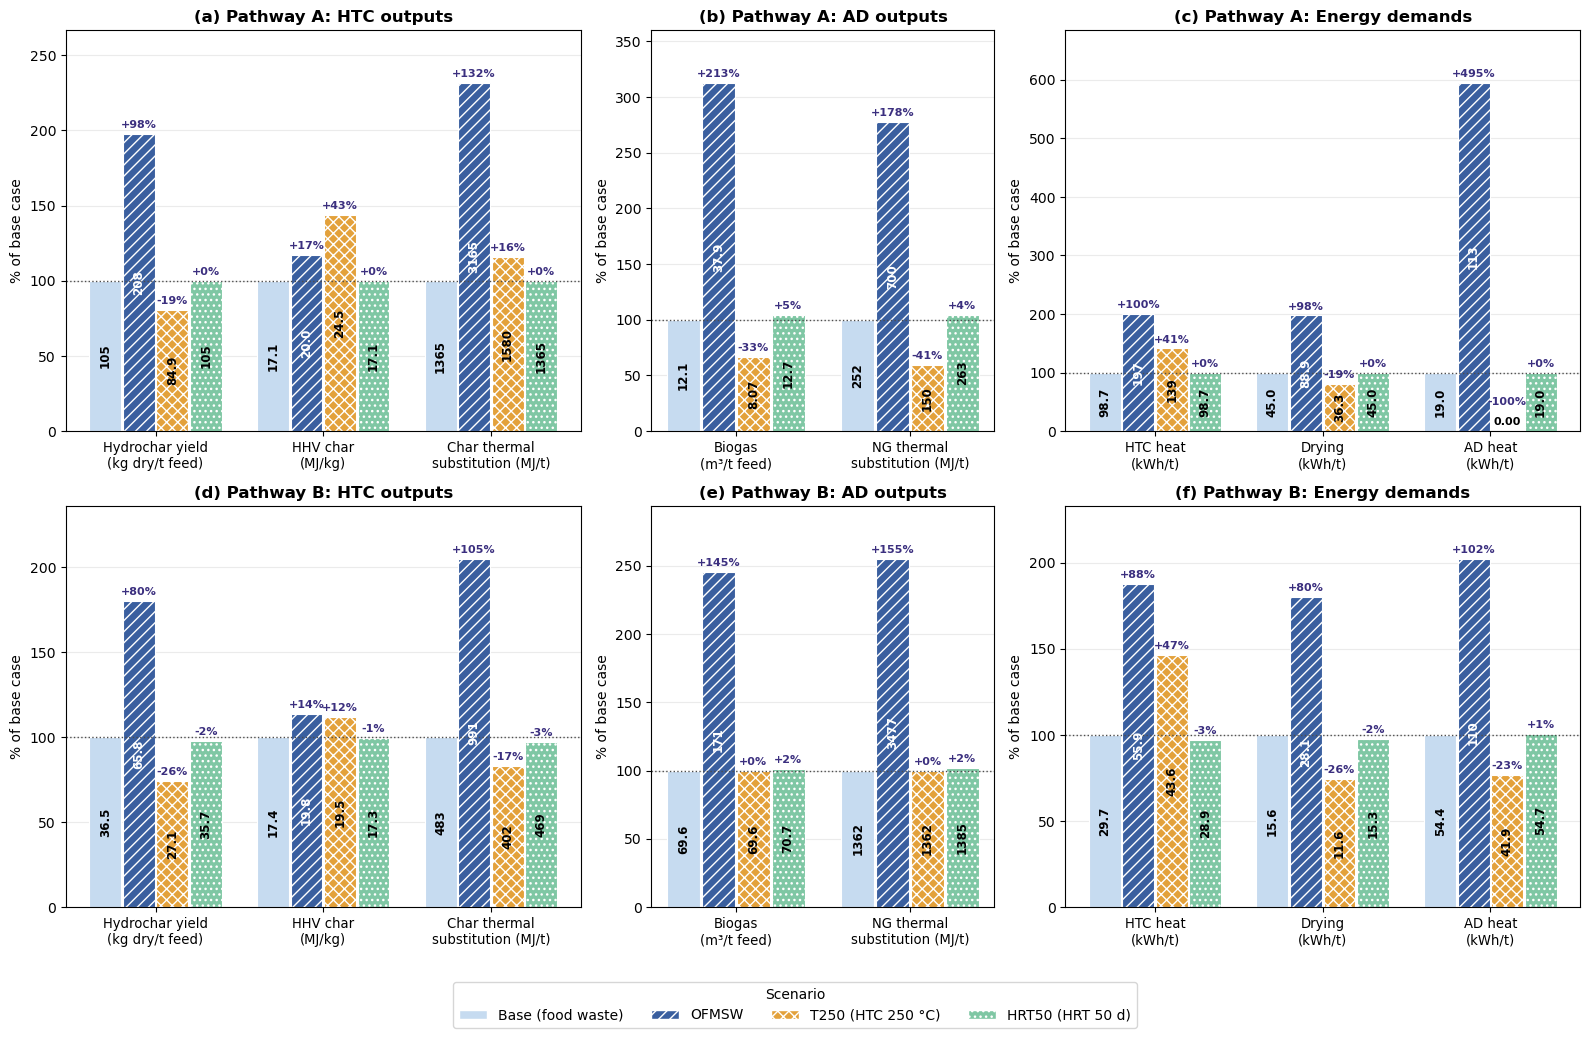

In [50]:
# =============================================================================
# 4. FIGURE 4: process outputs of both pathways, % of base case
#    (top row Pathway A, bottom row Pathway B)
# =============================================================================
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

mpl.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})   # embed fonts (journal requirement)
ROOT = Path.cwd() if (Path.cwd() / "ADM1").is_dir() else Path.cwd().parent   # repository root
df = pd.read_csv(ROOT / "results" / "case_study_results.csv").copy()

def scen_of(r):           # from the run inputs, independent of the 'scenario' text
    if r["feedstock"] == "ofmsw": return "OFMSW"
    if r["T_HTC"] == 250: return "T250"
    if r["HRT_d"] == 50: return "HRT50"
    return "Base"
df["scen"] = df.apply(scen_of, axis=1)
assert len(df) == 8 and df.groupby(["scen", "pathway"]).size().eq(1).all(), "expected one row per scenario x pathway"

SCEN = [("Base",  "Base (food waste)",  "#c6dbf0", ""),
        ("OFMSW", "OFMSW",              "#3a5f9f", "///"),
        ("T250",  "T250 (HTC 250 °C)",  "#e3a13b", "xxx"),
        ("HRT50", "HRT50 (HRT 50 d)",   "#7fc7a4", "...")]
INCLUDE_DRYING = True
PANELS = {
    "HTC outputs": [
        ("Hydrochar yield\n(kg dry/t feed)",  lambda r: r["HC_dry_mass_kg"]),
        ("HHV char\n(MJ/kg)",                 lambda r: r["char HHV_char (MJ/kg)"]),
        ("Char thermal\nsubstitution (MJ/t)", lambda r: r["MJ_hydrochar"])],
    "AD outputs": [
        ("Biogas\n(m³/t feed)",               lambda r: r["biogas_m3"]),
        ("NG thermal\nsubstitution (MJ/t)",   lambda r: r["biomethane_m3"] * r["LHV_biomethane_MJ_Nm3"])],
    "Energy demands": [("HTC heat\n(kWh/t)", lambda r: r["E_HTC_elec_kWh"])]
        + ([("Drying\n(kWh/t)", lambda r: r["E_dryer_heat_kWh"])] if INCLUDE_DRYING else [])
        + [("AD heat\n(kWh/t)", lambda r: r["Q_heat_AD_MJ"] / 3.6)],
}

def fmt(v):
    return f"{v:.0f}" if abs(v) >= 100 else f"{v:.1f}" if abs(v) >= 10 else f"{v:.2f}"

def draw_row(axes, pw, letters):
    sub = df[df["pathway"] == pw].set_index("scen")
    w = 0.2
    for ax, letter, (title, items) in zip(axes, letters, PANELS.items()):
        # values and % of base for the whole panel first, so label offsets scale with the axis
        data = []
        for gi, (lab, fn) in enumerate(items):
            vals = [float(fn(sub.loc[s])) for s, *_ in SCEN]
            assert all(np.isfinite(vals)) and min(vals) >= 0, f"{pw} {lab}: invalid values {vals}"
            assert vals[0] > 0, f"{pw} {lab}: base case is zero, % of base undefined"
            data.append((gi, vals, [100 * v / vals[0] for v in vals]))
        ytop = max(100, max(p for _, _, pcts in data for p in pcts)) * 1.15
        off = 0.02 * ytop
        for gi, vals, pcts in data:
            for k, ((s, name, col, hatch), v, pct) in enumerate(zip(SCEN, vals, pcts)):
                x = gi + (k - 1.5) * w
                ax.bar(x, pct, w * 0.95, color=col, hatch=hatch, edgecolor="white", linewidth=0.8)
                if pct >= 25:      # value written inside the bar, % change just above it
                    ax.text(x, pct / 2, fmt(v), rotation=90, ha="center", va="center", fontsize=8.5,
                            fontweight="bold", color="white" if k == 1 else "black")
                    top = pct + off / 2
                else:              # short or zero bar: value above the bar, % change stacked above the value
                    ax.text(x, pct + off / 2, fmt(v), ha="center", va="bottom", fontsize=8, fontweight="bold")
                    top = pct + off / 2 + 0.05 * ytop
                if k > 0:
                    ax.text(x, top, f"{pct - 100:+.0f}%", ha="center", va="bottom", fontsize=8,
                            color="#3b2f7f", fontweight="bold")
        ax.axhline(100, ls=":", color="0.3", lw=1)
        ax.set_xticks(range(len(items))); ax.set_xticklabels([l for l, _ in items], fontsize=9.5)
        ax.set_ylim(0, ytop); ax.set_ylabel("% of base case")
        ax.set_title(f"({letter}) Pathway {pw}: {title}", fontweight="bold", fontsize=12)
        ax.grid(axis="y", color="0.92"); ax.set_axisbelow(True)

fig, axes = plt.subplots(2, 3, figsize=(16, 10.4),
                         gridspec_kw={"width_ratios": [3, 2, len(PANELS["Energy demands"])]})
draw_row(axes[0], "A", "abc")
draw_row(axes[1], "B", "def")
fig.legend(handles=[Patch(facecolor=c, hatch=h, edgecolor="white", label=n) for _, n, c, h in SCEN],
           loc="lower center", ncol=4, title="Scenario", bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=[0, 0.07, 1, 1])
out = ROOT / "figures"; out.mkdir(exist_ok=True)
for ext in ("png", "pdf"):
    fig.savefig(out / f"Figure4_process_outputs.{ext}", dpi=300 if ext == "png" else None, bbox_inches="tight")
plt.show()

## 5. Figure 5: LCA results by contribution

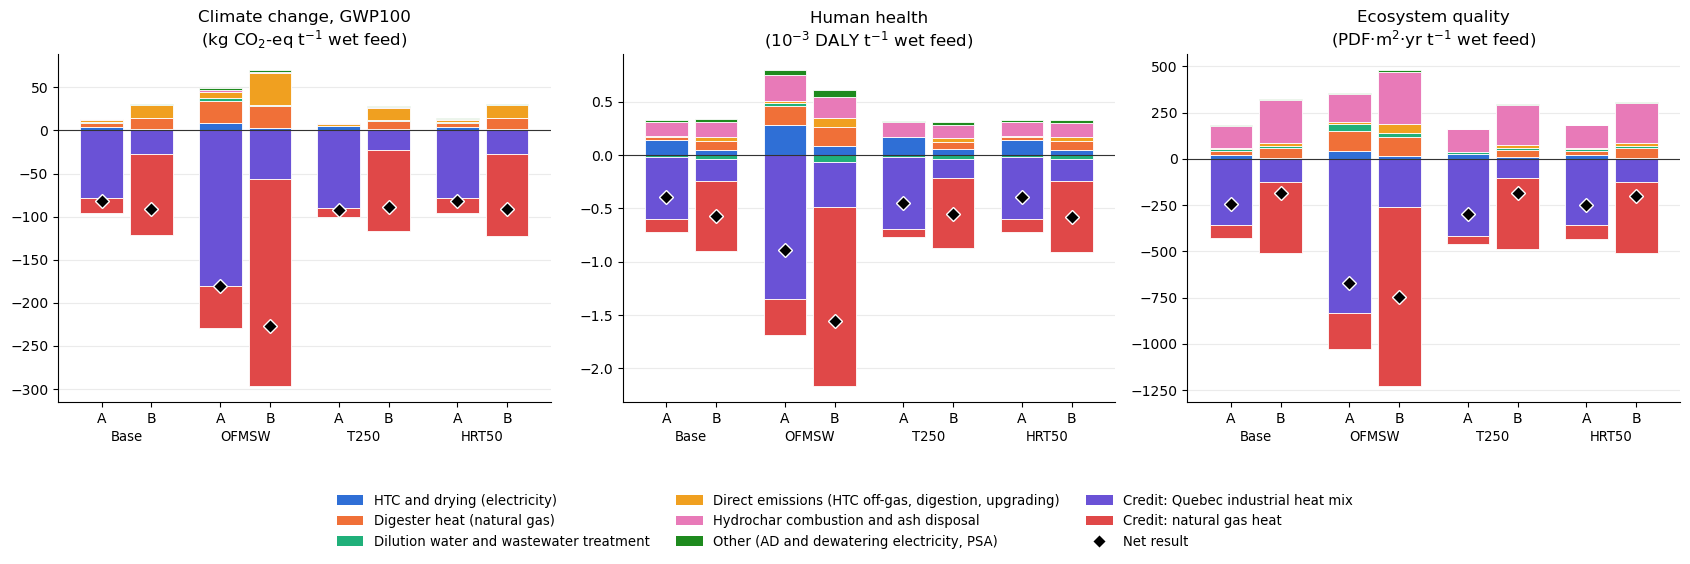

In [47]:
# =============================================================================
# 5. FIGURE 5: LCA results by contribution, both pathways, all scenarios
# =============================================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "ADM1").is_dir() else Path.cwd().parent   # repository root
c = pd.read_csv(ROOT / "results" / "case_study_contributions.csv")
res = pd.read_csv(ROOT / "results" / "case_study_results.csv")

SCEN = [("S1 Base FW", "Base"), ("S2 OFMSW", "OFMSW"),
        ("S3 HTC 250 C", "T250"), ("S4 HRT 50 d", "HRT50")]
IND = [("GWP100 (kg CO2 eq)", "Climate change, GWP100\n(kg CO$_2$-eq t$^{-1}$ wet feed)", 1.0),
       ("Human health (DALY)", "Human health\n(10$^{-3}$ DALY t$^{-1}$ wet feed)", 1e3),
       ("Ecosystem quality (PDF.m2.yr)", "Ecosystem quality\n(PDF·m$^2$·yr t$^{-1}$ wet feed)", 1.0)]
CAT_COL = {
    "HTC and drying (electricity)": "#2f6fd6",
    "Digester heat (natural gas)": "#f07038",
    "Dilution water and wastewater treatment": "#20b07a",
    "Direct emissions (HTC off-gas, digestion, upgrading)": "#f0a020",
    "Hydrochar combustion and ash disposal": "#e87ab8",
    "Other (AD and dewatering electricity, PSA)": "#1e8a1e",
    "Credit: Quebec industrial heat mix": "#6a52d6",
    "Credit: natural gas heat": "#e04848",
}

# QA: known categories, and the breakdown closes on the LCA scores
assert set(c["category"]) <= set(CAT_COL), f"unknown categories {set(c['category']) - set(CAT_COL)}"
for (s, p, ind), grp in c.groupby(["scenario", "pathway", "indicator"]):
    r = res[(res["pathway"] == p) & (res["scenario"] == s)]
    assert len(r) == 1, f"no single results row for {s}-{p}"
    tot, ref = grp["value"].sum(), r[ind].iloc[0]
    assert abs(tot - ref) <= 1e-4 * max(1e-9, abs(ref)), f"{s}-{p} {ind}: breakdown {tot} vs LCA {ref}"
ww = c[(c["category"] == "Dilution water and wastewater treatment") & (c["indicator"] == "GWP100 (kg CO2 eq)")]
if (ww["value"] <= 0).any():
    print("[QA] water/wastewater GWP contribution is not positive in some runs: check the sign of the "
          "wastewater treatment exchanges (ecoinvent waste treatments have production -1)")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
w, gap = 0.36, 0.06
for ax, (ind, title, sc) in zip(axes, IND):
    for gi, (s, lab) in enumerate(SCEN):
        for k, p in enumerate(("A", "B")):
            x = gi + (k - 0.5) * (w + gap)
            d = c[(c["scenario"] == s) & (c["pathway"] == p) & (c["indicator"] == ind)].set_index("category")["value"] * sc
            pos = neg = 0.0
            for cat, col in CAT_COL.items():
                v = float(d.get(cat, 0.0))
                if v >= 0:
                    ax.bar(x, v, w, bottom=pos, color=col, edgecolor="white", linewidth=0.6); pos += v
                else:
                    ax.bar(x, v, w, bottom=neg, color=col, edgecolor="white", linewidth=0.6); neg += v
            ax.plot(x, d.sum(), "D", color="black", ms=7, mec="white", mew=1, zorder=5)
    ax.axhline(0, color="0.2", lw=0.8)
    ax.set_xticks([gi + dx for gi in range(len(SCEN)) for dx in (-(w + gap) / 2, (w + gap) / 2)])
    ax.set_xticklabels(["A", "B"] * len(SCEN), fontsize=10)
    for gi, (_, lab) in enumerate(SCEN):
        ax.text(gi, -0.08, lab, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9.5)
    ax.set_title(title, fontsize=12)
    ax.grid(axis="y", color="0.92"); ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
handles = [Patch(facecolor=col, label=cat) for cat, col in CAT_COL.items()]
handles.append(Line2D([], [], marker="D", ls="", color="black", mec="white", ms=7, label="Net result"))
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=[0, 0.16, 1, 1])
out = ROOT / "figures"; out.mkdir(exist_ok=True)
for ext in ("png", "pdf"):
    fig.savefig(out / f"Figure5_LCA_contributions.{ext}", dpi=300, bbox_inches="tight")
plt.show()


## 6. LCA Inventory Table

In [40]:
# =============================================================================
# 6. LIFE CYCLE INVENTORY TABLE: all 8 runs, per t wet feed
# =============================================================================
import numpy as np, pandas as pd
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "ADM1").is_dir() else Path.cwd().parent   # repository root
df = pd.read_csv(ROOT / "results" / "case_study_results.csv").copy()
WC_NATIVE = {"food_waste": 0.85, "ofmsw": 0.70}      # case study feedstocks
F_FUG_NH3 = 0.05                                     # system_builder.build_ad_exchanges

def scen_of(r):
    if r["feedstock"] == "ofmsw": return "OFMSW"
    if r["T_HTC"] == 250: return "T250"
    if r["HRT_d"] == 50: return "HRT50"
    return "Base"
df["col"] = df.apply(lambda r: f"{scen_of(r)}-{r['pathway']}", axis=1)
assert df["col"].is_unique and len(df) == 8, f"expected 8 unique runs, got {list(df['col'])}"

def v(r, c):
    return r[c] if c in r and pd.notna(r[c]) else np.nan
A = lambda r: r["pathway"] == "A"

ROWS = [  # (section, item, unit, function of the results row)
    ("Inputs", "Feedstock, wet", "kg", lambda r: v(r, "m_feedstock")),
    ("Inputs", "Feedstock, dry matter", "kg", lambda r: v(r, "m_feedstock") * (1 - WC_NATIVE[r["feedstock"]])),
    ("Inputs", "Tap water, added before HTC", "kg", lambda r: v(r, "added_water_HTC")),
    ("Inputs", "Tap water, AD dilution", "kg",
        lambda r: v(r, "dilution_water_PW_m3") * 1000 if A(r) else v(r, "dilution_water_AD_kg")),
    ("Inputs", "Electricity, HTC heating", "kWh", lambda r: v(r, "E_HTC_elec_kWh")),
    ("Inputs", "Electricity, hydrochar drying (thermal duty)", "kWh", lambda r: v(r, "E_dryer_heat_kWh")),
    ("Inputs", "Electricity, dryer fan and press", "kWh", lambda r: v(r, "dryer_fan_press_kWh")),
    ("Inputs", "Heat, natural gas, AD", "MJ", lambda r: v(r, "Q_heat_AD_MJ")),
    ("Inputs", "Electricity, AD", "kWh", lambda r: v(r, "E_elec_AD_kWh")),
    ("Inputs", "Electricity, digestate dewatering", "kWh", lambda r: np.nan if A(r) else v(r, "E_centrifuge_kWh")),
    ("Inputs", "Biogas to PSA upgrading", "m3", lambda r: v(r, "biogas_m3")),
    ("HTC", "HTC temperature", "°C", lambda r: v(r, "T_HTC")),
    ("HTC", "HTC feed, wet", "kg", lambda r: v(r, "m_feedstock_effective")),
    ("HTC", "Hydrochar yield", "% dry", lambda r: v(r, "char Y_char (%)")),
    ("HTC", "Hydrochar, dry", "kg", lambda r: v(r, "HC_dry_mass_kg")),
    ("HTC", "Hydrochar HHV", "MJ/kg dry", lambda r: v(r, "char HHV_char (MJ/kg)")),
    ("HTC", "Hydrochar C", "% dry", lambda r: v(r, "char C_char (%)")),
    ("HTC", "Hydrochar H", "% dry", lambda r: v(r, "char H_char (%)")),
    ("HTC", "Hydrochar O", "% dry", lambda r: v(r, "char O_char (%)")),
    ("HTC", "Hydrochar N", "% dry", lambda r: v(r, "char N_char (%)")),
    ("HTC", "Hydrochar S", "% dry", lambda r: v(r, "char S_char (%)")),
    ("HTC", "Hydrochar ash", "% dry", lambda r: v(r, "char Ash_char (%)")),
    ("HTC", "Process water", "kg", lambda r: v(r, "PW_yield")),
    ("AD", "Hydraulic retention time", "d", lambda r: v(r, "HRT_d")),
    ("AD", "Digester pH (steady state)", "-", lambda r: v(r, "ADM1 pH")),
    ("AD", "CH4 produced", "kg", lambda r: v(r, "CH4_mass_AD")),
    ("AD", "CO2 in biogas", "kg", lambda r: v(r, "CO2_mass_AD")),
    ("AD", "Dewatered cake to HTC", "kg", lambda r: np.nan if A(r) else v(r, "m_cake_dewater_kg")),
    ("AD", "Centrate to wastewater treatment", "kg", lambda r: np.nan if A(r) else v(r, "m_centrate_dewater_kg")),
    ("AD", "AD effluent to wastewater treatment (A)", "kg",
    lambda r: (v(r, "dilution_water_PW_m3") * 1000 + v(r, "PW_yield")
               - v(r, "CH4_mass_AD") - v(r, "CO2_mass_AD")) if A(r) else np.nan),
    ("HTC", "HTC process water to wastewater treatment (B)", "kg",
        lambda r: np.nan if A(r) else v(r, "PW_yield")),
    ("HTC", "Dryer condensate to wastewater treatment", "m3", lambda r: v(r, "wastewater_drying_m3")),
    ("Emissions", "CO2, non-fossil, HTC off-gas", "kg", lambda r: v(r, "CO2_yield_HTC")),
    ("Emissions", "CO, non-fossil, HTC off-gas", "kg", lambda r: v(r, "CO_yield_HTC")),
    ("Emissions", "CH4, non-fossil, AD fugitive", "kg", lambda r: v(r, "CH4_fugitive_kg")),
    ("Emissions", "NH3, digester gas line (5% of gaseous NH3)", "kg", lambda r: v(r, "NH3_mass_AD") * F_FUG_NH3),
    ("Emissions", "CO2, non-fossil, hydrochar combustion", "kg", lambda r: v(r, "enduse_CO2_bio_kg")),
    ("Emissions", "SO2, hydrochar combustion", "kg", lambda r: v(r, "enduse_SO2_comb_kg")),
    ("Emissions", "NOx, hydrochar combustion", "kg", lambda r: v(r, "enduse_NOx_comb_kg")),
    ("Emissions", "PM, hydrochar combustion", "kg", lambda r: v(r, "enduse_PM_comb_kg")),
    ("Emissions", "Boiler ash to disposal", "kg", lambda r: v(r, "enduse_ash_kg")),
    ("Products", "Biomethane", "Nm3", lambda r: v(r, "biomethane_m3")),
    ("Products", "Heat from biomethane, avoids natural gas heat", "MJ",
        lambda r: v(r, "biomethane_m3") * v(r, "LHV_biomethane_MJ_Nm3")),
    ("Products", "Heat from hydrochar, avoids Quebec industrial heat mix", "MJ", lambda r: v(r, "MJ_hydrochar")),
]

ORDER = [f"{s}-{p}" for p in ("A", "B") for s in ("Base", "OFMSW", "T250", "HRT50")]
rows = []
for sec, item, unit, fn in ROWS:
    rec = {"Section": sec, "Item": item, "Unit": unit}
    for _, r in df.iterrows():
        try:
            rec[r["col"]] = float(fn(r))
        except (KeyError, TypeError, ValueError):
            rec[r["col"]] = np.nan
    rows.append(rec)
lci = pd.DataFrame(rows)[["Section", "Item", "Unit"] + ORDER]

# QA: physical bounds and dry-matter consistency
num = lci[ORDER]
neg = lci.loc[(num < 0).any(axis=1), "Item"].tolist()
assert not neg, f"negative inventory values in: {neg}"
pct = lci["Unit"].eq("% dry")
assert ((num[pct] >= 0) & (num[pct] <= 100)).all().all(), "a % dry value is outside 0-100"
for c in ORDER:
    r = df[df["col"] == c].iloc[0]
    if r["pathway"] == "A":   # HTC dry in = feedstock dry (water addition conserves dry matter)
        dry_htc = r["m_feedstock_effective"] * (1 - r["char WC_feed (%)"] / 100)
        dry_in = r["m_feedstock"] * (1 - WC_NATIVE[r["feedstock"]])
        assert abs(dry_htc - dry_in) < 1e-3 * dry_in, f"{c}: HTC dry {dry_htc:.2f} kg != feed dry {dry_in:.2f} kg"
empty = lci.loc[num.isna().all(axis=1), "Item"].tolist()
if empty:
    print("[QA] rows with no data in the CSV (column missing): ", empty)

pd.set_option("display.width", 250, "display.max_rows", 100)
display(lci.style.format({c: "{:.4g}" for c in ORDER}, na_rep="–").hide(axis="index"))
lci.to_csv(ROOT / "results" / "LCI_table.csv", index=False)
try:
    lci.to_excel(ROOT / "results" / "LCI_table.xlsx", index=False)
    print(f"Saved -> {ROOT / 'results' / 'LCI_table.xlsx'} and .csv")
except ImportError:
    print(f"Saved -> {ROOT / 'results' / 'LCI_table.csv'} (install openpyxl for .xlsx)")

Section,Item,Unit,S1-A,S2-A,S3-A,S4-A,S1-B,S2-B,S3-B,S4-B
Inputs,"Feedstock, wet",kg,1000,1000,1000,1000,1000,1000,1000,1000
Inputs,"Feedstock, dry matter",kg,150,300,150,150,150,300,150,150
Inputs,"Tap water, added before HTC",kg,0,1000,0,0,0,0,0,0
Inputs,"Tap water, AD dilution",kg,1929,6022,983.7,1929,875,2750,875,875
Inputs,"Electricity, HTC heating",kWh,98.69,197.4,139.3,98.69,29.75,55.91,43.63,28.94
Inputs,"Electricity, hydrochar drying (thermal duty)",kWh,44.98,88.87,36.29,44.98,15.61,28.13,11.59,15.25
Inputs,"Electricity, dryer fan and press",kWh,6.455,12.75,5.208,6.455,2.24,4.037,1.663,2.188
Inputs,"Heat, natural gas, AD",MJ,68.51,407.9,0,68.51,195.9,396.5,150.9,196.9
Inputs,"Electricity, AD",kWh,16.57,46.15,11.01,16.57,11.25,22.5,11.25,11.25
Inputs,"Electricity, digestate dewatering",kWh,–,–,–,–,5.361,10.62,5.361,5.357


Saved -> LCI_table.xlsx and .csv


## 7. SI: hydrochar substituting hard coal heat

Per MJ of heat: {'coal | GWP100': '0.125', 'mix | GWP100': '0.0571', 'coal | Human health': '1.07e-06', 'mix | Human health': '4.27e-07', 'coal | Ecosystem quality': '0.546', 'mix | Ecosystem quality': '0.263'}


hard_coal                                                                                              quebec_mix                                                                         
indicator    Ecosystem quality (PDF.m2.yr)              GWP100 (kg CO2 eq)             Human health (DALY)           Ecosystem quality (PDF.m2.yr)             GWP100 (kg CO2 eq)             Human health (DALY)          
pathway                                  A            B                  A           B                   A         B                             A           B                  A           B                   A         B
scenario                                                                                                                                                                                                                   
S1 Base FW                     -632.521613  -320.143884        -173.711234 -123.479646           -0.001264 -0.000876                   -246.389451 -183.438557         -81.523585  -90.841746           -0.000391 -0.000566
S2 OFMSW                      -1566.091045 -1027.050590        -393.858300 -293.281327           -0.002915 -0.002194                   -670.882852 -746.863788        -180.130600 -226.387747           -0.000890 -0.001560
S3 HTC 250 C                   -742.480329  -300.225098        -198.574845 -116.048453           -0.001458 -0.000813                   -295.469078 -186.589652         -91.852535  -88.918404           -0.000447 -0.000556
S4 HRT 50 d                    -635.442376  -331.572940        -174.357061 -123.045148           -0.001269 -0.000879                   -249.310214 -198.803199         -82.169412  -91.346855           -0.000396 -0.000578

GWP100 (kg CO2 eq)               quebec_mix better pathway: {'S1 Base FW': 'B', 'S2 OFMSW': 'B', 'S3 HTC 250 C': 'A', 'S4 HRT 50 d': 'B'}
GWP100 (kg CO2 eq)               hard_coal  better pathway: {'S1 Base FW': 'A', 'S2 OFMSW': 'A', 'S3 HTC 250 C': 'A', 'S4 HRT 50 d': 'A'}
Human health (DALY)              quebec_mix better pathway: {'S1 Base FW': 'B', 'S2 OFMSW': 'B', 'S3 HTC 250 C': 'B', 'S4 HRT 50 d': 'B'}
Human health (DALY)              hard_coal  better pathway: {'S1 Base FW': 'A', 'S2 OFMSW': 'A', 'S3 HTC 250 C': 'A', 'S4 HRT 50 d': 'A'}
Ecosystem quality (PDF.m2.yr)    quebec_mix better pathway: {'S1 Base FW': 'A', 'S2 OFMSW': 'B', 'S3 HTC 250 C': 'A', 'S4 HRT 50 d': 'A'}
Ecosystem quality (PDF.m2.yr)    hard_coal  better pathway: {'S1 Base FW': 'A', 'S2 OFMSW': 'A', 'S3 HTC 250 C': 'A', 'S4 HRT 50 d': 'A'}


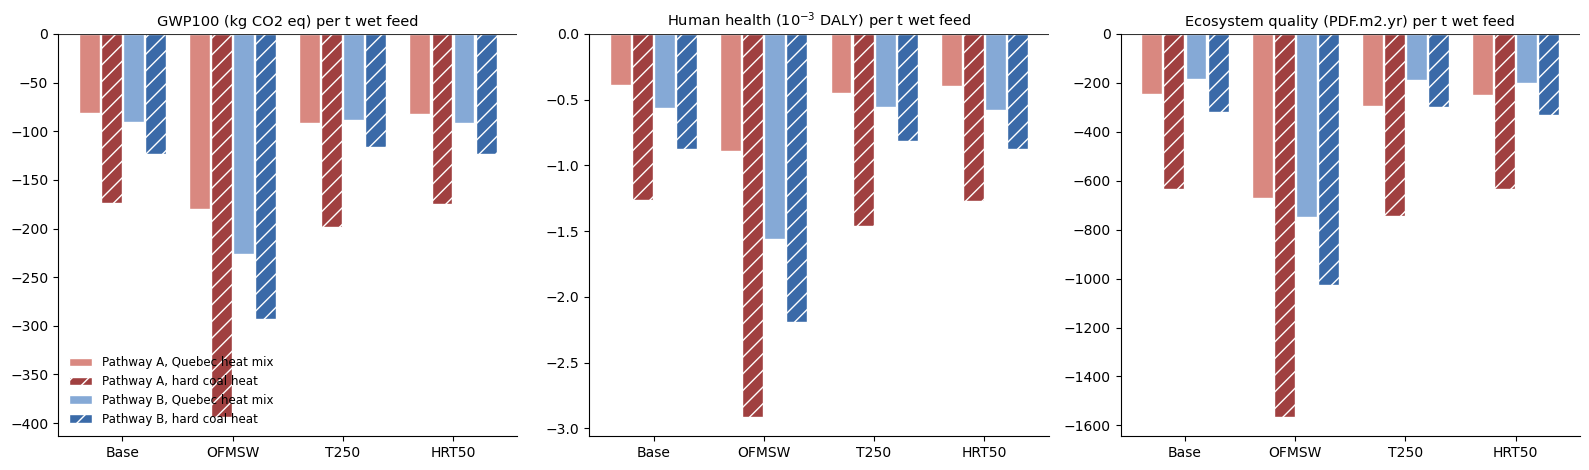

In [48]:
# =============================================================================
# 7. SI: hydrochar substituting hard coal heat (needs Brightway, ~1 min)
#   Exact swap of the hydrochar credit: credit = -MJ_hydrochar x (score of 1 MJ).
#   Run before section 8 (which rebuilds the foreground databases).
# =============================================================================
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
import bw2data as bd
from bw2calc import LCA

ROOT = os.getcwd() if os.path.isdir(os.path.join(os.getcwd(), "ADM1")) else os.path.dirname(os.getcwd())   # repository root
bd.projects.set_current("ei3.12 for DDI")
M = {"GWP100 (kg CO2 eq)": ("IMPACT World+ Midpoint 2.2.1_regionalized for ecoinvent v3.12", "Midpoint", "Climate change, short term"),
     "Human health (DALY)": ("IMPACT World+ Damage 2.2.1_regionalized for ecoinvent v3.12", "Human health", "Total human health"),
     "Ecosystem quality (PDF.m2.yr)": ("IMPACT World+ Damage 2.2.1_regionalized for ecoinvent v3.12", "Ecosystem quality", "Total ecosystem quality")}
ei = bd.Database("ecoinvent-3.12-cutoff")
coal = next(a for a in ei if a["name"] == "heat production, at hard coal industrial furnace 1-10MW" and a["location"] == "CA-QC")
mix = bd.Database("PathwayA").get("qc_industrial_heat_mix")
unit = {}
for k, m in M.items():
    for act, lab in ((coal, "coal"), (mix, "mix")):
        l = LCA({act: 1}, m); l.lci(); l.lcia(); unit[(lab, k)] = l.score

res = pd.read_csv(os.path.join(ROOT, "results", "case_study_results.csv"))
con = pd.read_csv(os.path.join(ROOT, "results", "case_study_contributions.csv"))
rows = []
for _, r in res.iterrows():
    for k in M:
        mix_credit = con[(con.scenario == r.scenario) & (con.pathway == r.pathway) & (con.indicator == k)
                         & (con.category == "Credit: Quebec industrial heat mix")]["value"].iloc[0]
        # QA: the stored credit must equal -MJ x unit score of the mix (same model, same run)
        expect = -r["MJ_hydrochar"] * unit[("mix", k)]
        assert abs(mix_credit - expect) <= 1e-3 * max(1e-12, abs(expect)), \
            f"[coal SI] {r.scenario}-{r.pathway} {k}: stored mix credit {mix_credit:.4g} != {expect:.4g}"
        coal_credit = -r["MJ_hydrochar"] * unit[("coal", k)]
        rows.append(dict(scenario=r.scenario, pathway=r.pathway, indicator=k,
                         quebec_mix=r[k], hard_coal=r[k] - mix_credit + coal_credit))
coal_si = pd.DataFrame(rows)
print("Per MJ of heat:", {f"{a} | {k.split(' (')[0]}": f"{v:.3g}" for (a, k), v in unit.items()})
wide = coal_si.pivot_table(index="scenario", columns=["indicator", "pathway"], values=["quebec_mix", "hard_coal"])
display(wide)
for k in M:                                            # which pathway wins under each substitution
    for sub in ("quebec_mix", "hard_coal"):
        t = coal_si[coal_si.indicator == k].pivot(index="scenario", columns="pathway", values=sub)
        print(f"{k:32s} {sub:10s} better pathway: {dict(zip(t.index, np.where(t['A'] < t['B'], 'A', 'B')))}")
coal_si.to_csv(os.path.join(ROOT, "results", "SI_coal_substitution.csv"), index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
SC = ["S1 Base FW", "S2 OFMSW", "S3 HTC 250 C", "S4 HRT 50 d"]
STY = {("A", "quebec_mix"): ("#d98880", ""), ("A", "hard_coal"): ("#a04040", "//"),
       ("B", "quebec_mix"): ("#85a9d6", ""), ("B", "hard_coal"): ("#3a6aa8", "//")}
SCALE = {"Human health (DALY)": 1e3}
for ax, k in zip(axes, M):
    for i, (key, (col, h)) in enumerate(STY.items()):
        p, sub = key
        vals = [coal_si[(coal_si.scenario == s) & (coal_si.pathway == p) & (coal_si.indicator == k)][sub].iloc[0] * SCALE.get(k, 1) for s in SC]
        ax.bar(np.arange(4) + (i - 1.5) * 0.2, vals, 0.19, color=col, hatch=h, edgecolor="white",
               label=f"Pathway {p}, {'Quebec heat mix' if sub == 'quebec_mix' else 'hard coal heat'}")
    ax.axhline(0, color="0.2", lw=0.8)
    ax.set_xticks(range(4)); ax.set_xticklabels(["Base", "OFMSW", "T250", "HRT50"])
    ax.set_title(k.replace("(DALY)", "(10$^{-3}$ DALY)") + " per t wet feed", fontsize=10.5)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(fontsize=8.5, frameon=False, loc="lower left")
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(ROOT, "figures", f"FigureS6_coal_substitution.{ext}"), dpi=300, bbox_inches="tight")
plt.show()

## 8. Sensitivity analysis (Figures 6, S7 and S8)

54 runs to do (0 already done)


ADM1 continuous:  25%|████████████████                                                | 150/600 [00:20<01:00,  7.43d/s]


[1/54] A Baseline  Baseline               0     ok  QA: HC_atomic = 2.006 outside training p1-p99 [0.64, 1.97]; OC_atomic = 0.842 outside training p1-p99 [0.07, 0.83]


ADM1 continuous:  25%|████████████████                                                | 150/600 [00:13<00:41, 10.92d/s]


[2/54] B Baseline  Baseline               0     ok


ADM1 continuous:  24%|███████████████▍                                                | 145/599 [00:15<00:47,  9.51d/s]


... (95 outputs left out)

ADM1 continuous:  25%|████████████████                                                | 150/600 [00:18<00:56,  8.00d/s]


[53/54] A PW-ADM1   K_I (all sub-pools)    +20%  ok  QA: HC_atomic = 2.006 outside training p1-p99 [0.64, 1.97]; OC_atomic = 0.842 outside training p1-p99 [0.07, 0.83]


ADM1 continuous:  25%|████████████████                                                | 150/600 [00:18<00:55,  8.13d/s]


[54/54] A PW-ADM1   Sub-pool composition   +20%  ok  QA: HC_atomic = 2.006 outside training p1-p99 [0.64, 1.97]; OC_atomic = 0.842 outside training p1-p99 [0.07, 0.83]
[QA] baselines reproduce case study S1 within 0.1 %


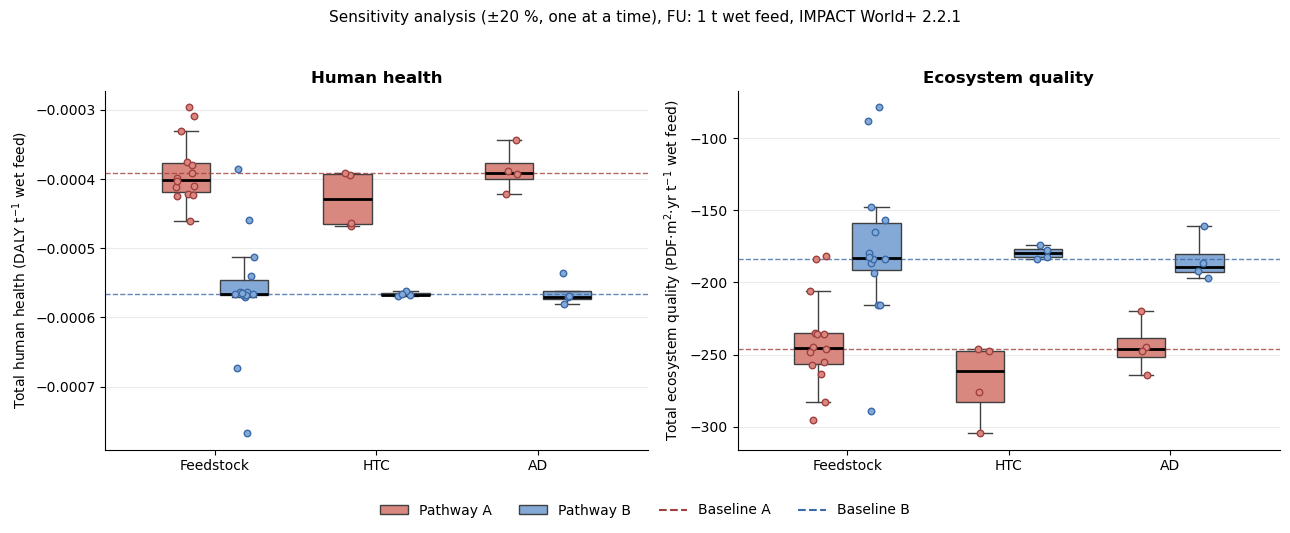

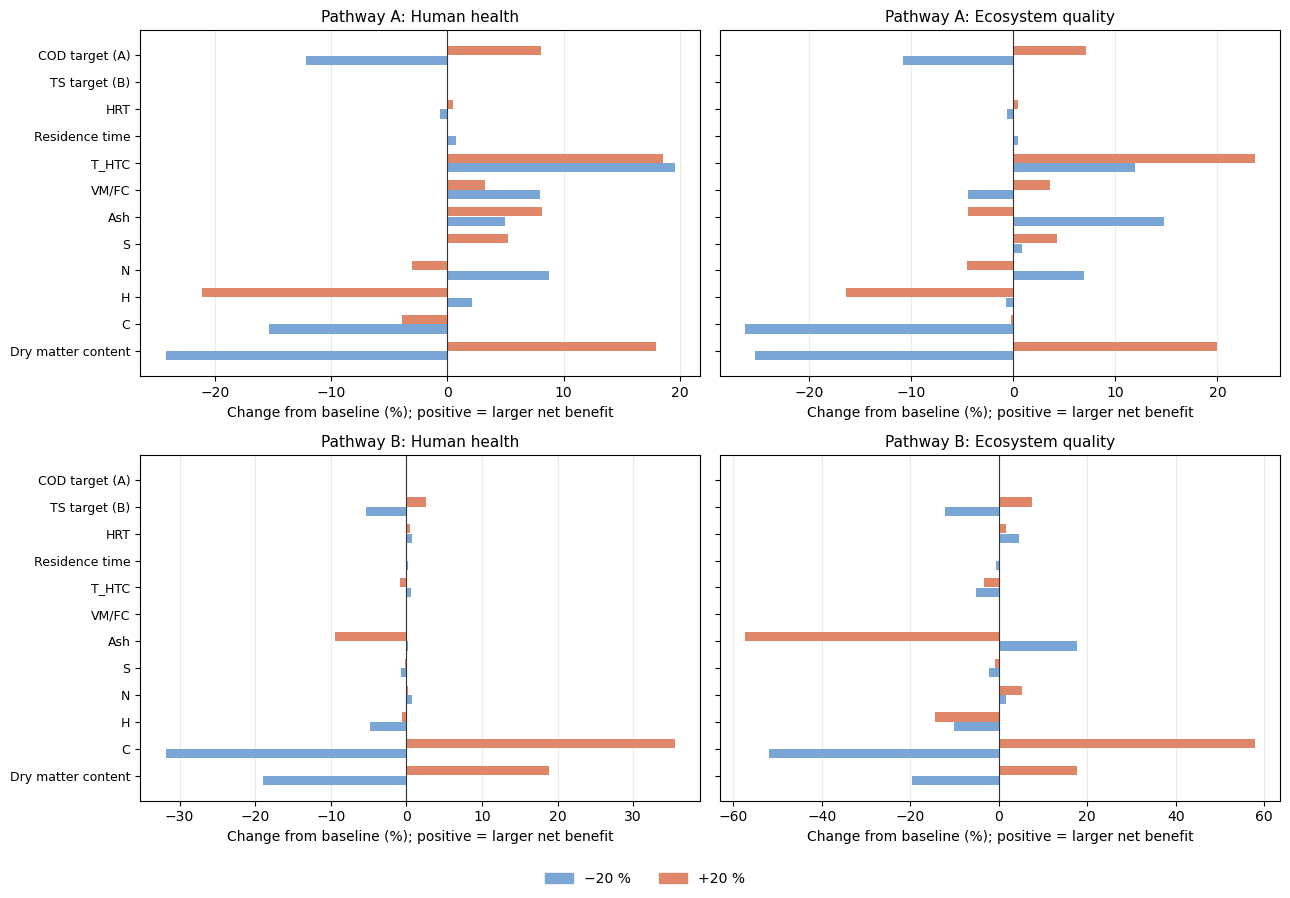


PW-ADM1 assumptions, Pathway A, change from baseline (%):


Ecosystem quality (PDF.m2.yr) change (%)        GWP100 (kg CO2 eq) change (%)        Human health (DALY) change (%)       
direction                                                +20%   -20%                          +20%   -20%                           +20%   -20%
parameter                                                                                                                                      
K_I (all sub-pools)                                     0.020 -0.032                         0.013 -0.021                          0.021 -0.034
S_I fraction                                           -0.678  0.678                        -0.455  0.455                         -0.722  0.721
Sub-pool composition                                    0.041 -0.047                         0.027 -0.032                          0.044 -0.051
f_slow                                                 -0.360  0.360                        -0.240  0.240                         -0.386  0.386

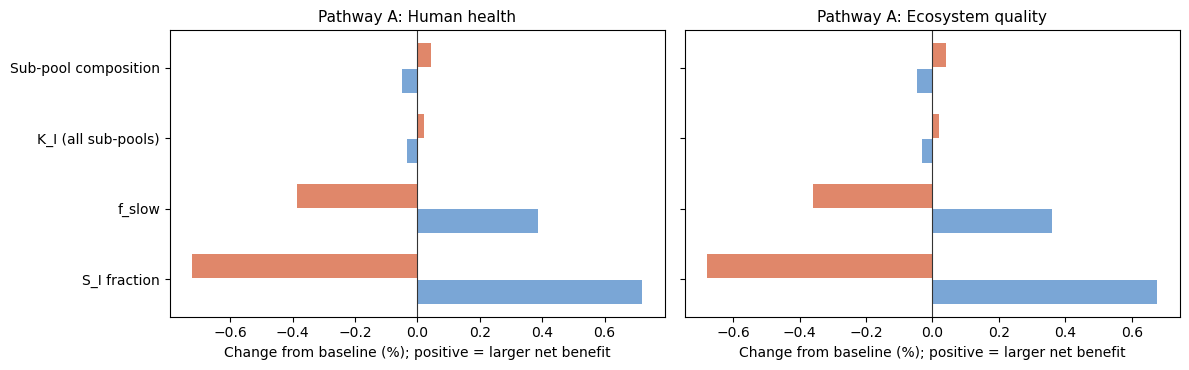


Range of results per group and pathway (per t wet feed):


Human health (DALY)           Ecosystem quality (PDF.m2.yr)             GWP100 (kg CO2 eq)           
                                  min       max                           min         max                min        max
group     pathway                                                                                                      
AD        A                 -0.000422 -0.000344                   -264.022792 -219.775778         -85.519526 -75.495473
          B                 -0.000581 -0.000536                   -197.131866 -161.150849         -92.376166 -86.697262
Feedstock A                 -0.000461 -0.000296                   -295.493629 -181.866317         -97.788504 -64.394713
          B                 -0.000768 -0.000386                   -289.453479  -78.418745        -119.661575 -65.865192
HTC       A                 -0.000467 -0.000391                   -304.609997 -246.382082         -92.920281 -81.522248
          B                 -0.000570 -0.000561                   -183.438557 -174.131096         -91.749071 -90.841746


Number of shared perturbations where the pathway ranking flips vs baseline: {'Human health (DALY)': 0, 'Ecosystem quality (PDF.m2.yr)': 1, 'GWP100 (kg CO2 eq)': 3}


In [45]:
# =============================================================================
# 8. SENSITIVITY ANALYSIS: one at a time, +/-20 % around the Base scenario (food waste)
#    Figure 6 (groups, both pathways), Figure S7 (each parameter), Figure S8 (PW-ADM1)
#    Run after section 2 in the same kernel (uses its settings, datasets and foreground()).
#    59 runs, about 1 min each. Results are saved after every run; if the cell is
#    interrupted, rerun it and it continues where it stopped.
# =============================================================================
import os, io, copy, contextlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from bw2calc import LCA

OUT_SENS = os.path.join(HADES_DIR, "results", "sensitivity_OAT.csv")
FIG_DIR = os.path.join(HADES_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)
DELTA = 0.20
ADM1M = sb._adm1_core                      # the ADM1 module instance used by system_builder
BASE = dict(feed=dict(FEEDS["food_waste"]), T_HTC=180, RT=FIXED["RT_HTC"], HRT=30,
            TS=FIXED["TS_target"], COD=FIXED["COD_conc_target"])

# ---------------------------------------------------------------- feedstock helpers
def with_O(f):
    f = dict(f)
    f["O_feed"] = 100 - f["C_feed"] - f["H_feed"] - f["N_feed"] - f["S_feed"] - f["Ash_feed"]
    return f

def check_feed(f, tag):
    """Physical bounds of a perturbed feedstock; raises instead of running nonsense."""
    errs = []
    if not 0 < f["WC"] < 100: errs.append(f"WC={f['WC']:.2f} %")
    if f["O_feed"] <= 0: errs.append(f"O by difference={f['O_feed']:.2f} %")
    tot = f["VM_feed"] + f["FC_feed"] + f["Ash_feed"]
    if abs(tot - 100) > 0.5: errs.append(f"VM+FC+Ash={tot:.2f} %")
    if errs:
        raise ValueError(f"[sensitivity | {tag}] invalid feedstock: {errs}")

def feed_variant(param, f):
    b = dict(BASE["feed"])
    if param == "Dry matter content":            # solids +/-20 % (moisture itself would exceed 100 %)
        b["WC"] = 100 - (100 - b["WC"]) * f
    elif param in ("C", "H", "N", "S"):
        b[f"{param}_feed"] *= f
    elif param == "Ash":                         # VM and FC rescaled so VM + FC + ash = 100
        new_ash = b["Ash_feed"] * f
        k = (100 - new_ash) / (b["VM_feed"] + b["FC_feed"])
        b["Ash_feed"], b["VM_feed"], b["FC_feed"] = new_ash, b["VM_feed"] * k, b["FC_feed"] * k
    elif param == "VM/FC":                       # ratio +/-20 %, VM + FC kept constant
        tot, r = b["VM_feed"] + b["FC_feed"], b["VM_feed"] / b["FC_feed"] * f
        b["FC_feed"] = tot / (1 + r); b["VM_feed"] = tot - b["FC_feed"]
    return b

# ---------------------------------------------------------------- PW-ADM1 assumption patches (restored after each run)
@contextlib.contextmanager
def pw_patch(kind, f):
    P = ADM1M.PW_ADM1_PARAMS
    saved_P, saved_C = dict(P), copy.deepcopy(ADM1M.SI_COMPOSITION)
    orig = ADM1M.derive_adm1_fractions
    try:
        if kind == "S_I fraction":
            def wrapped(*a, **k):
                fr = orig(*a, **k)
                if k.get("substrate_type") == "htc_pw":
                    sI, XI = fr["S_I"], fr["X_I"]
                    new = min(sI * f, 1 - XI - 1e-9)
                    g = (1 - new - XI) / (1 - sI - XI)
                    for key in fr:
                        if key not in ("S_I", "X_I"):
                            fr[key] *= g
                    fr["S_I"] = new
                    assert abs(sum(fr.values()) - 1) < 1e-9, "S_I patch broke fraction closure"
                return fr
            ADM1M.derive_adm1_fractions = wrapped
        elif kind == "f_slow":                   # base value at 180 C is 0.40 (manuscript text)
            P["f_slow_override"] = 0.40 * f
        elif kind == "K_I (all sub-pools)":
            for key in list(P):
                if key.startswith("K_I_"):
                    P[key] *= f
        elif kind == "Sub-pool composition":     # toxic pools (furan, phenol, ketone) +/-20 %, renormalized
            for sp in ("furan", "phenol", "ketone"):
                ADM1M.SI_COMPOSITION[sp] = [v * f for v in ADM1M.SI_COMPOSITION[sp]]
        else:
            raise ValueError(kind)
        yield
    finally:
        P.clear(); P.update(saved_P)
        ADM1M.SI_COMPOSITION.clear(); ADM1M.SI_COMPOSITION.update(saved_C)
        ADM1M.derive_adm1_fractions = orig

# ---------------------------------------------------------------- run list
def run_list():
    runs = [dict(group="Baseline", parameter="Baseline", direction="0", cfg=BASE, pw=None, pathways=("A", "B"))]
    for d, f in (("-20%", 1 - DELTA), ("+20%", 1 + DELTA)):
        for p in ("Dry matter content", "C", "H", "N", "S", "Ash", "VM/FC"):
            runs.append(dict(group="Feedstock", parameter=p, direction=d,
                             cfg={**BASE, "feed": feed_variant(p, f)}, pw=None, pathways=("A", "B")))
        runs.append(dict(group="HTC", parameter="T_HTC", direction=d, cfg={**BASE, "T_HTC": BASE["T_HTC"] * f}, pw=None, pathways=("A", "B")))
        runs.append(dict(group="HTC", parameter="Residence time", direction=d, cfg={**BASE, "RT": BASE["RT"] * f}, pw=None, pathways=("A", "B")))
        runs.append(dict(group="AD", parameter="HRT", direction=d, cfg={**BASE, "HRT": BASE["HRT"] * f}, pw=None, pathways=("A", "B")))
        runs.append(dict(group="AD", parameter="TS target (B)", direction=d, cfg={**BASE, "TS": BASE["TS"] * f}, pw=None, pathways=("B",)))
        runs.append(dict(group="AD", parameter="COD target (A)", direction=d, cfg={**BASE, "COD": BASE["COD"] * f}, pw=None, pathways=("A",)))
        for k in ("S_I fraction", "f_slow", "K_I (all sub-pools)", "Sub-pool composition"):
            runs.append(dict(group="PW-ADM1", parameter=k, direction=d, cfg=BASE, pw=(k, f), pathways=("A",)))
    return runs

def run_one(P, cfg):
    feed = with_O(cfg["feed"]); check_feed(feed, f"{P}")
    FG, fg = foreground(P)
    ctx = sb.SystemContext(
        ei=ei, bios=bios, FOREGROUND_DB=FG, **bg, co2_air=co2_air, co_air=co_air, **fg,
        PATHWAY=P, m_feedstock=1000.0, default_params=feed,
        ml_params={**feed, "T": cfg["T_HTC"], "RT": cfg["RT"]},
        T_HTC=cfg["T_HTC"], RT_HTC=cfg["RT"], target_moisture_HTC=FIXED["target_moisture_HTC"],
        MC_char=FIXED["MC_char"], target_MC_char_dry=FIXED["target_MC_char_dry"],
        COD_conc_target=cfg["COD"], ISR_batch=FIXED["ISR_batch"], feedstock_name="food_waste",
        heat_mix_components_qc=heat_mix_qc, ash_disposal=ash_disposal,
        location_country="Canada", location_province="quebec", location_code="CA-QC")
    ss = sb.spinup_ss_state(ctx, pathway=P, adm1_HRT_days=cfg["HRT"], t_spinup=FIXED["t_spinup"],
                            TS_target=cfg["TS"], verbose=False, ml_module=ML_MODULE)
    wt, _, adm1_out, _, inv = sb.build_system(
        ctx, ml_module=ML_MODULE, adm1_mode="continuous", adm1_HRT_days=cfg["HRT"],
        adm1_ss_state=ss, ISR_batch=FIXED["ISR_batch"], TS_target=cfg["TS"])
    out = {k: None for k in METHODS}
    for k, m in METHODS.items():
        l = LCA({wt: 1}, m); l.lci(); l.lcia(); out[k] = l.score
    data = dict(getattr(wt, "_data", wt))
    for k in ("HC_dry_mass_kg", "MJ_hydrochar", "biomethane_m3", "biogas_m3", "qa_flags"):
        out[k] = data.get(k)
    out["char_in_training_range"] = inv.get("in_training_range")
    return out

# ---------------------------------------------------------------- run (resumable)
done = pd.read_csv(OUT_SENS) if os.path.exists(OUT_SENS) else pd.DataFrame()
key = lambda P, r: (P, r["group"], r["parameter"], r["direction"])
have = set() if done.empty else {(a, b, c, str(d)) for a, b, c, d, s in
        done[["pathway", "group", "parameter", "direction", "status"]].itertuples(index=False) if s == "ok"}
rows = [] if done.empty else done[done["status"] == "ok"].to_dict("records")
todo = [(P, r) for r in run_list() for P in r["pathways"] if key(P, r) not in have]
print(f"{len(todo)} runs to do ({len(have)} already done)")
for i, (P, r) in enumerate(todo, 1):
    rec = dict(pathway=P, group=r["group"], parameter=r["parameter"], direction=r["direction"], status="ok")
    try:
        buf = io.StringIO()
        with contextlib.redirect_stdout(buf):
            if r["pw"]:
                with pw_patch(*r["pw"]):
                    rec.update(run_one(P, r["cfg"]))
            else:
                rec.update(run_one(P, r["cfg"]))
    except Exception as e:
        rec["status"] = f"FAILED: {type(e).__name__}: {e}"
    rows.append(rec)
    pd.DataFrame(rows).to_csv(OUT_SENS, index=False)
    print(f"[{i}/{len(todo)}] {P} {r['group']:9s} {r['parameter']:22s} {r['direction']:5s} {rec['status'][:70]}"
          + (f"  QA: {rec.get('qa_flags')}" if rec.get("qa_flags") else ""))

sens = pd.DataFrame(rows)
bad = sens[sens["status"] != "ok"]
if len(bad):
    print(f"\n[QA] {len(bad)} runs failed; they are excluded from the figures:\n",
          bad[["pathway", "parameter", "direction", "status"]].to_string(index=False))
sens = sens[sens["status"] == "ok"].copy()

# ---------------------------------------------------------------- QA: baseline reproduces the Base scenario
IND = ["Human health (DALY)", "Ecosystem quality (PDF.m2.yr)", "GWP100 (kg CO2 eq)"]
res_cs = pd.read_csv(OUT_CSV)
for P in ("A", "B"):
    b = sens[(sens.pathway == P) & (sens.group == "Baseline")]
    cs = res_cs[(res_cs.pathway == P) & (res_cs.scenario == "S1 Base FW")]
    assert len(b) == 1, f"no baseline run for pathway {P}"
    for k in IND:
        if len(cs) == 1:
            rel = abs(b[k].iloc[0] / cs[k].iloc[0] - 1)
            assert rel < 1e-3, f"[QA] baseline {P} {k} differs from the Base scenario by {rel:.2%}"
print("[QA] baselines reproduce the Base scenario within 0.1 %")

base = {P: sens[(sens.pathway == P) & (sens.group == "Baseline")].iloc[0] for P in ("A", "B")}
for k in IND:
    sens[f"{k} change (%)"] = [100 * (r[k] / base[r.pathway][k] - 1) for _, r in sens.iterrows()]

# ---------------------------------------------------------------- Figure 6: groups, both pathways
COL = {"A": "#d98880", "B": "#85a9d6"}; EDGE = {"A": "#a04040", "B": "#3a6aa8"}
GROUPS = ["Feedstock", "HTC", "AD"]
FIG8 = [("Human health (DALY)", "Total human health (DALY t$^{-1}$ wet feed)", "Human health"),
        ("Ecosystem quality (PDF.m2.yr)", "Total ecosystem quality (PDF·m$^2$·yr t$^{-1}$ wet feed)", "Ecosystem quality")]
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, len(FIG8), figsize=(13, 5.2))
for ax, (k, ylab, title) in zip(axes, FIG8):
    for gi, g in enumerate(GROUPS):
        for j, P in enumerate(("A", "B")):
            v = sens[(sens.group == g) & (sens.pathway == P)][k].values
            if len(v) == 0:
                continue
            x = gi + (j - 0.5) * 0.36
            ax.boxplot(v, positions=[x], widths=0.3, patch_artist=True, showfliers=False,
                       boxprops=dict(facecolor=COL[P], edgecolor="0.25"), medianprops=dict(color="black", lw=2),
                       whiskerprops=dict(color="0.25"), capprops=dict(color="0.25"))
            ax.scatter(x + rng.uniform(-0.06, 0.06, len(v)), v, s=22, color=COL[P], edgecolor=EDGE[P], zorder=3)
    for P in ("A", "B"):
        ax.axhline(base[P][k], ls="--", lw=1, color=EDGE[P], alpha=0.8)
    ax.set_xticks(range(len(GROUPS))); ax.set_xticklabels(GROUPS)
    ax.set_ylabel(ylab); ax.set_title(title, fontweight="bold")
    ax.grid(axis="y", color="0.92"); ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
handles = [Patch(facecolor=COL["A"], edgecolor="0.25", label="Pathway A"), Patch(facecolor=COL["B"], edgecolor="0.25", label="Pathway B"),
           Line2D([], [], ls="--", color=EDGE["A"], label="Baseline A"), Line2D([], [], ls="--", color=EDGE["B"], label="Baseline B")]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Sensitivity analysis (±20 %, one at a time), FU: 1 t wet feed, IMPACT World+ 2.2.1", fontsize=11)
fig.tight_layout(rect=[0, 0.06, 1, 0.95])
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(FIG_DIR, f"Figure6_sensitivity_OAT.{ext}"), dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------- Figure S7: each parameter (% change vs baseline)
op = sens[sens.group.isin(GROUPS)]
params = list(dict.fromkeys(op["parameter"]))
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
for col, (k, _, title) in enumerate(FIG8):
    for row, P in enumerate(("A", "B")):
        ax = axes[row, col]
        for yi, p in enumerate(params):
            for d, c in (("-20%", "#7aa6d6"), ("+20%", "#e0876a")):
                s = op[(op.pathway == P) & (op.parameter == p) & (op.direction == d)]
                if len(s):
                    ax.barh(yi + (-0.18 if d == "-20%" else 0.18), s[f"{k} change (%)"].iloc[0], 0.34, color=c)
        ax.axvline(0, color="0.2", lw=0.8)
        ax.set_yticks(range(len(params))); ax.set_yticklabels(params, fontsize=9)
        ax.invert_yaxis()
        ax.set_title(f"Pathway {P}: {title}", fontsize=11)
        ax.set_xlabel("Change from baseline (%); positive = larger net benefit")
        ax.grid(axis="x", color="0.92"); ax.set_axisbelow(True)
fig.legend(handles=[Patch(color="#7aa6d6", label="−20 %"), Patch(color="#e0876a", label="+20 %")],
           loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0.04, 1, 1])
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(FIG_DIR, f"FigureS7_sensitivity_parameters.{ext}"), dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------- Figure S8: PW-ADM1 assumptions (Pathway A)
pw = sens[(sens.group == "PW-ADM1") & (sens.pathway == "A")]
tab = pw.pivot_table(index="parameter", columns="direction",
                     values=[f"{k} change (%)" for k in IND])
print("\nPW-ADM1 assumptions, Pathway A, change from baseline (%):")
display(tab.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
pwp = list(dict.fromkeys(pw["parameter"]))
for ax, (k, _, title) in zip(axes, FIG8):
    for yi, p in enumerate(pwp):
        for d, c in (("-20%", "#7aa6d6"), ("+20%", "#e0876a")):
            s = pw[(pw.parameter == p) & (pw.direction == d)]
            if len(s):
                ax.barh(yi + (-0.18 if d == "-20%" else 0.18), s[f"{k} change (%)"].iloc[0], 0.34, color=c)
    ax.axvline(0, color="0.2", lw=0.8)
    ax.set_yticks(range(len(pwp))); ax.set_yticklabels(pwp); ax.invert_yaxis()
    ax.set_title(f"Pathway A: {title}", fontsize=11); ax.set_xlabel("Change from baseline (%); positive = larger net benefit")
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(FIG_DIR, f"FigureS8_sensitivity_PWADM1.{ext}"), dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------- numbers for the text
summ = (sens[sens.group.isin(GROUPS)].groupby(["group", "pathway"])[IND].agg(["min", "max"]))
print("\nRange of results per group and pathway (per t wet feed):")
display(summ)
cross = {}
for k in IND:
    a = sens[sens.pathway == "A"].set_index(["parameter", "direction"])[k]
    b = sens[sens.pathway == "B"].set_index(["parameter", "direction"])[k]
    both = a.index.intersection(b.index)
    cross[k] = int(((a[both] < b[both]) != (base["A"][k] < base["B"][k])).sum())
print("\nNumber of shared perturbations where the pathway ranking flips vs baseline:", cross)

## 9. SI: energy, mass and carbon balances

In [46]:
# =============================================================================
# 9. SI (CSV only, no Brightway): energy balance with heat integration,
# mass balance per unit, carbon partition in HTC (Pathway A), per t wet feed.
# Can run in a second notebook while section 8 runs.
# =============================================================================
import os, numpy as np, pandas as pd
ROOT = os.getcwd() if os.path.isdir(os.path.join(os.getcwd(), "ADM1")) else os.path.dirname(os.getcwd())   # repository root
r = pd.read_csv(os.path.join(ROOT, "results", "case_study_results.csv"))
r["col"] = r["scenario"].str[:2] + "-" + r["pathway"]
r = r.set_index("col").loc[[f"S{i}-{p}" for p in "AB" for i in range(1, 5)]]
MC_WET, MC_DRY = 0.35, 0.10        # hydrochar moisture after pressing / after drying (as in section 2)

# ---------------------------------------------------------------- energy balance (MJ/t wet feed)
E = pd.DataFrame({
    "Feed temperature entering HTC (°C)": r["T_feed_HTC_C"],
    "HTC sensible heat demand, gross": r["Q_HTC_gross_MJ"],
    "HTC heat recovered (product to feed, eps = %.2f)" % r["eps_HR_used"].iloc[0]: r["Q_HTC_rec_MJ"],
    "HTC net heat demand": r["Q_HTC_net_MJ"],
    "HTC electricity (MJ)": r["E_HTC_elec_kWh"] * 3.6,
    "Dryer thermal duty": r["Q_dry_util_MJ"],
    "Dryer fan and press electricity (MJ)": (r["E_dry_fan_kWh"] + r["E_press_kWh"]) * 3.6,
    "AD heat demand (heating + losses)": r["Q_AD_dem_MJ"],
    "AD heat recovered from HTC products": r["Q_AD_rec_MJ"],
    "AD heat losses": r["Q_AD_loss_MJ"],
    "AD heat from natural gas": r["Q_AD_util_MJ"],
    "AD inlet temperature (°C)": r["T_AD_inlet_C"],
    "Surplus heat rejected": r["Q_surplus_rejected_MJ"],
    "AD electricity (MJ)": r["E_elec_AD_kWh"] * 3.6,
    "Heat delivered by hydrochar": r["MJ_hydrochar"],
    "Heat delivered by biomethane": r["biomethane_m3"] * r["LHV_biomethane_MJ_Nm3"],
    "Energy closure residual": r["energy_closure_residual_MJ"],
}).T
# QA: heat-integration identities and bounds
assert np.allclose(r["Q_HTC_gross_MJ"] - r["Q_HTC_rec_MJ"] - r["Q_HTC_rxn_MJ"], r["Q_HTC_net_MJ"], atol=1e-3), "HTC heat balance"
assert np.allclose(np.maximum(r["Q_AD_dem_MJ"] - r["Q_AD_rec_MJ"], 0), r["Q_AD_util_MJ"], atol=1e-2), "AD heat balance"
assert (r["energy_closure_residual_MJ"].abs() < 1e-3).all(), "energy closure residual != 0"
eff = r["Q_HTC_net_MJ"] / (r["E_HTC_elec_kWh"] * 3.6)
print(f"Implied efficiency of electric HTC heating: {eff.min():.3f} to {eff.max():.3f}")
display(E.round(1))

# ---------------------------------------------------------------- mass balance (kg/t wet feed)
rows = {}
for c, x in r.iterrows():
    hc_wet, hc_dried = x["HC_dry_mass_kg"] / (1 - MC_WET), x["HC_dry_mass_kg"] / (1 - MC_DRY)
    gas_htc = x["CO2_yield_HTC"] + x["CO_yield_HTC"]
    biogas = x["CH4_mass_AD"] + x["CO2_mass_AD"]
    if x["pathway"] == "A":
        water_in = x["added_water_HTC"] + x["dilution_water_PW_m3"] * 1000
        htc_in, htc_out = x["m_feedstock"] + x["added_water_HTC"], x["PW_yield"] + gas_htc + hc_wet
        effluent = x["PW_yield"] + x["dilution_water_PW_m3"] * 1000 - biogas
    else:
        water_in = x["dilution_water_AD_kg"]
        htc_in, htc_out = x["m_cake_dewater_kg"], x["PW_yield"] + gas_htc + hc_wet
        effluent = x["m_centrate_dewater_kg"] + x["PW_yield"]
    rows[c] = {"Feed": x["m_feedstock"], "Tap water": water_in,
               "HTC in": htc_in, "HTC out": htc_out, "HTC closure (%)": 100 * (htc_out / htc_in - 1),
               "Hydrochar, dried (10 % moisture)": hc_dried, "Water evaporated in dryer": hc_wet - hc_dried,
               "HTC off-gas": gas_htc, "Biogas": biogas, "Liquid to wastewater treatment": effluent,
               "Total out": hc_dried + (hc_wet - hc_dried) + gas_htc + biogas + effluent}
MB = pd.DataFrame(rows)
MB.loc["Overall closure (%)"] = 100 * (MB.loc["Total out"] / (MB.loc["Feed"] + MB.loc["Tap water"]) - 1)
display(MB.round(2))
bad = MB.columns[(MB.loc["HTC closure (%)"].abs() > 0.5) | (MB.loc["Overall closure (%)"].abs() > 0.5)]
print("[QA] mass balance closes within 0.5 % in all runs" if bad.empty else f"[QA] mass balance off by > 0.5 % in {list(bad)}")

# ---------------------------------------------------------------- carbon partition in HTC, Pathway A (% of feed C)
# needs FEEDS from section 2; skipped in a separate notebook
cp = {}
if "FEEDS" in globals():
    for c, x in r[r["pathway"] == "A"].iterrows():
        f = FEEDS[x["feedstock"]]
        c_in = x["m_feedstock"] * (1 - f["WC"] / 100) * f["C_feed"] / 100
        c_char = x["HC_dry_mass_kg"] * x["char C_char (%)"] / 100
        c_gas = x["CO2_yield_HTC"] * 12.011 / 44.009 + x["CO_yield_HTC"] * 12.011 / 28.010
        cp[c] = {"Hydrochar": 100 * c_char / c_in, "Off-gas": 100 * c_gas / c_in,
                 "Process water (by difference)": 100 * (1 - (c_char + c_gas) / c_in)}
    CP = pd.DataFrame(cp)
    assert (CP >= 0).all().all(), f"negative carbon share (process water C by difference < 0):\n{CP}"
    display(CP.round(1))
else:
    CP = pd.DataFrame()
    print("FEEDS not defined: carbon partition skipped (run this cell in the case study notebook)")

with pd.ExcelWriter(os.path.join(ROOT, "results", "SI_balances.xlsx")) as w:
    E.round(3).to_excel(w, sheet_name="Energy balance (MJ per t)")
    MB.round(3).to_excel(w, sheet_name="Mass balance (kg per t)")
    if not CP.empty:
        CP.round(2).to_excel(w, sheet_name="HTC carbon partition A")
print("Saved -> SI_balances.xlsx")

Implied efficiency of electric HTC heating: 0.900 to 0.900


col,S1-A,S2-A,S3-A,S4-A,S1-B,S2-B,S3-B,S4-B
Feed temperature entering HTC (°C),10.0,10.0,10.0,10.0,30.0,30.0,30.0,30.0
"HTC sensible heat demand, gross",710.6,1421.2,1003.2,710.6,214.2,402.5,314.2,208.3
"HTC heat recovered (product to feed, eps = 0.55)",390.8,781.7,551.8,390.8,117.8,221.4,172.8,114.6
HTC net heat demand,319.8,639.5,451.4,319.8,96.4,181.1,141.4,93.7
HTC electricity (MJ),355.3,710.6,501.6,355.3,107.1,201.3,157.1,104.2
Dryer thermal duty,161.9,319.9,130.7,161.9,56.2,101.3,41.7,54.9
Dryer fan and press electricity (MJ),23.2,45.9,18.7,23.2,8.1,14.5,6.0,7.9
AD heat demand (heating + losses),137.5,545.8,16.6,137.5,235.1,470.2,235.1,235.1
AD heat recovered from HTC products,69.0,137.9,16.6,69.0,39.3,73.8,84.3,38.2
AD heat losses,57.7,160.8,38.4,57.7,39.2,78.4,39.2,39.2


,S1-A,S2-A,S3-A,S4-A,S1-B,S2-B,S3-B,S4-B
Feed,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
Tap water,1929.23,7022.46,983.74,1929.23,875.00,2750.00,875.00,875.00
HTC in,1000.00,2000.00,1000.00,1000.00,341.62,642.01,341.62,332.27
HTC out,1000.00,2000.00,1000.00,1000.00,341.62,642.01,341.62,332.27
HTC closure (%),-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,0.00
"Hydrochar, dried (10 % moisture)",116.95,231.06,94.36,116.95,40.59,73.15,30.13,39.65
Water evaporated in dryer,44.98,88.87,36.29,44.98,15.61,28.13,11.59,15.25
HTC off-gas,5.16,10.32,17.87,5.16,1.75,3.30,6.06,1.70
Biogas,14.80,49.58,10.53,15.50,88.13,211.42,88.13,89.41
Liquid to wastewater treatment,2747.34,7642.63,1824.69,2746.64,1728.92,3434.00,1739.10,1728.99


[QA] mass balance closes within 0.5 % in all runs


,S1-A,S2-A,S3-A,S4-A
Hydrochar,73.3,77.2,74.5,73.3
Off-gas,2.5,2.1,8.7,2.5
Process water (by difference),24.2,20.6,16.9,24.2


Saved -> SI_balances.xlsx
